# Aprendizado Não Supervisionado e Clusterização
### Uma aula prática de ponta a ponta — de K-Means a Autoencoders com PyTorch + CUDA

---

## O que você vai aprender

Ao final deste notebook você será capaz de:

1. Explicar **o que é** aprendizado não supervisionado e por que ele difere do supervisionado.
2. Identificar as **famílias de problemas** não supervisionados (agrupamento, redução de dimensionalidade, detecção de anomalias, associação).
3. Definir formalmente **clusterização** e reconhecer os **tipos de cluster** (centroide, densidade, hierárquico, probabilístico, grafo).
4. Construir um pipeline completo: **problema → dados → EDA → pré-processamento → redução de dimensionalidade → treino → avaliação → interpretação → estabilidade**.
5. Treinar e **comparar mais de 15 algoritmos** de clusterização sob as mesmas métricas.
6. Implementar um **Autoencoder em PyTorch** com aceleração em GPU e usar o espaço latente como features para clusterização.
7. Avaliar clusters **sem rótulos** (métricas internas) e **com rótulos** (métricas externas), entendendo quando cada uma vale.

---

## Dataset

**MNIST** (70.000 imagens 28x28 de dígitos manuscritos, 784 atributos).
Usamos uma subamostra de 12.000 imagens por tempo de execução — o pipeline é idêntico para o dataset completo.

> O rótulo verdadeiro do dígito **não é usado no treino**. Ele existe apenas para *auditar* o resultado (métrica externa), simulando o cenário real: você não tem a resposta quando faz clusterização.

---

## Pré-requisitos

- Python 3.10+
- `numpy`, `pandas`, `matplotlib`, `seaborn`
- `scikit-learn`, `tabulate`, `openml`
- `torch` (com CUDA, se houver GPU)
- Opcionais: `scikit-learn-extra`, `scikit-fuzzy`, `hdbscan`

Instalação base: `pip install numpy pandas matplotlib seaborn scikit-learn openml tabulate`
Opcionais: `pip install scikit-learn-extra scikit-fuzzy hdbscan`

---

In [1]:
# ============================================================
# CÉLULA 2 — Ambiente, imports, seeds e verificação de GPU
# ============================================================
import sys, os, time, random, warnings, math
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

from sklearn.datasets import fetch_openml, load_digits

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans

from sklearn.decomposition import PCA

# ------------------------------------------------------------
# Reprodutibilidade: fixar todas as fontes de aleatoriedade
# ------------------------------------------------------------
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (9, 4.5),
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)


# ============================================================
# HELPERS DE MARKDOWN DINÂMICO
# ------------------------------------------------------------
# Estas duas funções são a base de todas as células 🧠 do
# notebook: elas transformam valores calculados em markdown.
# ============================================================
def md(texto: str) -> None:
    """Renderiza markdown gerado dinamicamente a partir de uma string Python."""
    display(Markdown(texto))


def tabela_md(df: pd.DataFrame, casas: int = 3) -> str:
    """Converte um DataFrame em tabela markdown, com fallback caso tabulate falte."""
    d = df.copy()
    for c in d.select_dtypes(include=[float]).columns:
        d[c] = d[c].round(casas)
    try:
        return d.to_markdown(index=False)
    except Exception as e:
        print(e)
        return e# d.to_string(index=False)


print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__}")

# ------------------------------------------------------------
# PyTorch + CUDA
# ------------------------------------------------------------
try:
    import torch
    import torch.nn as nn
    print(f"PyTorch {torch.__version__}")
    TEM_GPU = torch.cuda.is_available()
    if TEM_GPU:
        props = torch.cuda.get_device_properties(0)
        print(f"GPU  : {props.name}")
        print(f"CUDA : {torch.version.cuda} | Memória {props.total_memory/1e9:.1f} GB")
        DEVICE = torch.device("cuda")
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.benchmark = True   # kernels otimizados p/ entrada fixa
    else:
        DEVICE = torch.device("cpu")
        print("CUDA indisponível -> treino na CPU (mais lento, mesmo resultado)")
except ImportError:
    torch, nn, DEVICE, TEM_GPU = None, None, None, False
    print("PyTorch não instalado: pip install torch --index-url https://download.pytorch.org/whl/cu124")

print(f"\nDevice selecionado: {DEVICE}")

Python 3.11.9 | NumPy 1.26.4 | pandas 2.1.4
PyTorch 2.5.1+cu121
GPU  : NVIDIA GeForce GTX 1660 Ti
CUDA : 12.1 | Memória 6.4 GB

Device selecionado: cuda


# PARTE 1 — Fundamentos

## 1. O que é Aprendizado Não Supervisionado

Aprendizado de máquina supervisionado aprende a função que liga **X a y** — você tem as respostas.
O **não supervisionado** aprende a **estrutura interna de X**, sem nenhum y.

> **Definição:** dado um conjunto de observações $X = \{x_1, x_2, ..., x_n\}$, com
> $x_i \in \mathbb{R}^p$, o objetivo é encontrar padrões, agrupamentos, estruturas de baixa
> dimensão ou distribuições que expliquem os dados **sem variável-alvo**.

### Por que isso muda tudo

No supervisionado você mede sucesso com acurácia, F1, RMSE — existe um gabarito.
No não supervisionado **não existe gabarito**. Você precisa:

- Definir o que significa "parecido" (a métrica de distância é uma **decisão de modelagem**).
- Escolher quantos grupos existem (ou descobrir isso via critério).
- Interpretar o resultado (o algoritmo acha estrutura, não significado).

O algoritmo **não descobre a verdade** — ele descobre *uma* estrutura, segundo a sua definição de similaridade.

## 2. Taxonomia do Não Supervisionado

| Família | Objetivo | Pergunta típica | Algoritmos |
|---|---|---|---|
| **Agrupamento** | agrupar por similaridade | "quais perfis existem?" | K-Means, DBSCAN, GMM, Hierárquico |
| **Redução de dimensionalidade** | comprimir preservando estrutura | "quais são os fatores por trás?" | PCA, t-SNE, UMAP, Autoencoders |
| **Detecção de anomalias** | isolar o raro | "o que é atípico aqui?" | Isolation Forest, LOF, One-Class SVM |
| **Regras de associação** | relações item-item | "quem compra X compra Y" | Apriori, FP-Growth, Eclat |
| **Representação** | aprender features úteis | "como representar melhor?" | Autoencoders, embeddings, contrastive |

### Por que importa

1. **Volume:** a maior parte dos dados do mundo não tem rótulo. Rotular é caro, lento e especializado.
2. **Descoberta:** o supervisionado confirma o que você já suspeitava; o não supervisionado **revela o que você não sabia procurar**.
3. **Pré-processamento:** PCA e embeddings melhoram praticamente todo modelo supervisionado depois.
4. **Compressão e custo:** reduzir 784 dimensões para 32 acelera treino, reduz memória e viabiliza tempo real.
5. **Aplicações reais:** segmentação de clientes, detecção de fraude, agrupamento de notícias, análise de expressão gênica, manutenção preditiva, sistemas de recomendação, moderação de conteúdo.

## 3. Os Desafios Reais

- **Ausência de ground truth.** Não há um número que diga "acertou". Você valida por *estabilidade*, *coerência de negócio* e *métricas internas*.
- **Escolha da distância.** Euclidiana, cosseno, Manhattan, Gower, DTW... Cada uma define um universo diferente de clusters.
- **Maldição da dimensionalidade.** Em alta dimensão, as distâncias tendem a se igualar: todos os pontos ficam "igualmente longe". Isso destrói métodos baseados em distância — a razão pela qual **reduzir dimensionalidade antes de agrupar** é padrão de mercado.
- **Escala.** Um atributo em reais (0–100.000) domina um atributo em anos (0–80). Normalizar não é opcional.
- **Sensibilidade a sementes.** K-Means com seeds diferentes pode gerar partições diferentes. Teste estabilidade.
- **Escalabilidade.** Métodos hierárquicos são $O(n^2)$ em memória — inviáveis acima de dezenas de milhares de pontos sem amostragem.
- **Interpretação.** O cluster 3 existe; agora, o que ele *significa* para o negócio? Isso é trabalho humano, apoiado por evidências.

## 4. Clusterização: A Definição Formal

**Clusterizar** é particionar $n$ objetos em $k$ grupos de modo que:

- objetos **dentro** do mesmo grupo sejam **similares** entre si (alta coesão);
- objetos em grupos **diferentes** sejam **dissimilares** (alta separação).

Formalmente, uma partição $\mathcal{C} = \{C_1, ..., C_k\}$ tal que
$\bigcup_{i=1}^{k} C_i = X$ e $C_i \cap C_j = \emptyset$ para $i \neq j$.

O critério de K-Means, por exemplo, busca minimizar a inércia (soma dos quadrados intra-cluster):

$J = \sum_{i=1}^{k}\sum_{x \in C_i} \|x - \mu_i\|^2$

### Os 5 tipos de cluster (isso determina qual algoritmo faz sentido)

1. **Centroide / partição** — clusters convexos, esféricos, de tamanho parecido. *K-Means, K-Medoids.*
2. **Hierárquico** — clusters aninhados, com relação de parentesco. *Ward, Average, Complete.*
3. **Densidade** — clusters de forma arbitrária, com outliers explicitamente isolados. *DBSCAN, HDBSCAN, OPTICS.*
4. **Probabilístico** — cada ponto pertence a cada cluster com uma probabilidade. *GMM.*
5. **Grafo / conectividade** — clusters como componentes fortemente conectados. *Spectral.*

> **Regra de ouro:** escolher o algoritmo antes de olhar a forma dos dados é o erro nº 1 em clusterização.

## 5. As Métricas

### 5.1 Métricas INTERNAS (não usam rótulo — seu cenário real)

**Silhouette** — combina coesão e separação, entre -1 e 1:

$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$

onde $a(i)$ é a distância média de $i$ aos pontos do próprio cluster e $b(i)$ ao cluster vizinho mais próximo.

- $\approx 1$ → ponto bem alocado
- $\approx 0$ → ponto na fronteira
- $< 0$ → ponto provavelmente no cluster errado

**Calinski-Harabasz** (razão de variâncias) — quanto maior, melhor.  
**Davies-Bouldin** — quanto **menor**, melhor.  
**Inércia / WCSS** — sempre cai com k maior; serve só para o cotovelo.  

### 5.2 Métricas EXTERNAS (usam o rótulo verdadeiro — apenas para auditoria)

**ARI** (Adjusted Rand Index) — concordância de pares, corrigida para o acaso. 1 = perfeito, 0 = aleatório.  
**NMI** (Normalized Mutual Information) — informação compartilhada, 0 a 1.  

> ⚠️ **ARI/NMI não entram no critério de escolha do modelo em produção.** Servem para *validar metodologia*, não para escolher o cluster. Neste notebook mostramos as duas famílias separadas para você aprender a diferença na prática.

## 6. Como escolher o número de clusters

| Método | Como funciona | Limitação |
|---|---|---|
| **Cotovelo (Elbow)** | plotar inércia × k e achar a "dobra" | subjetivo |
| **Silhouette** | maximizar a média | favorece clusters convexos |
| **Calinski-Harabasz** | maximizar | cresce em dados ruidosos |
| **Gap Statistic** | compara com dados uniformes | custo computacional |
| **BIC/AIC** | para modelos probabilísticos (GMM) | depende do modelo |
| **Estabilidade** | reamostrar e medir concordância (ARI) | caro |

**Prática recomendada:** cruze pelo menos dois critérios + conhecimento de domínio. Se o negócio precisa de 5 segmentos acionáveis, 5 é um ponto de partida legítimo — desde que as métricas não o contradigam de forma gritante.

In [2]:
# ============================================================
# CÉLULA 9 — Motor de avaliação: métricas + executor de modelos
# ============================================================
def metricas_cluster(nome, labels, X_ref, y_ref=None, tempo=None, ruido=-1, obs=""):
    """Calcula o pacote completo de métricas para uma partição.

    Internas  -> silhouette, calinski, davies
    Externas  -> ARI, NMI (só quando y_ref existe; é auditoria, não treino)
    """
    labels = np.asarray(labels).ravel()
    X_ref = np.asarray(X_ref)

    linha = {
        "modelo": nome, "n": len(labels), "tempo_s": np.nan, "k": np.nan,
        "ruido_%": np.nan, "silhouette": np.nan, "calinski": np.nan,
        "davies": np.nan, "ARI": np.nan, "NMI": np.nan, "obs": obs,
    }
    if tempo is not None:
        linha["tempo_s"] = round(float(tempo), 2)

    # -1 é a convenção de "ruído" em DBSCAN/HDBSCAN/OPTICS
    validos = np.ones(len(labels), dtype=bool) if ruido is None else (labels != ruido)
    if ruido == -1 and (~validos).any():
        linha["ruido_%"] = round(100.0 * (~validos).mean(), 2)

    lv, Xv = labels[validos], X_ref[validos]
    k = len(np.unique(lv))
    linha["k"] = k

    if k >= 2 and len(lv) > k:
        try:
            linha["silhouette"] = round(float(silhouette_score(
                Xv, lv, sample_size=min(5000, len(lv)), random_state=SEED)), 4)
        except Exception:
            pass
        try:
            linha["calinski"] = round(float(calinski_harabasz_score(Xv, lv)), 1)
            linha["davies"]   = round(float(davies_bouldin_score(Xv, lv)), 4)
        except Exception:
            pass
        if y_ref is not None and len(y_ref) == len(labels):
            try:
                yr = np.asarray(y_ref)[validos]
                linha["ARI"] = round(float(adjusted_rand_score(yr, lv)), 4)
                linha["NMI"] = round(float(normalized_mutual_info_score(yr, lv)), 4)
            except Exception:
                pass
    return linha


def executar_modelo(nome, ctor, X, y, ruido, n=None):
    """Instancia, treina, cronometra e avalia um modelo. Nunca quebra o loop."""
    if n is None or n >= len(X):
        idx = np.arange(len(X))
    else:
        idx = np.random.default_rng(SEED).choice(len(X), n, replace=False)

    Xb = X[idx]
    yb = None if y is None else np.asarray(y)[idx]

    try:
        modelo = ctor()
        t0 = time.perf_counter()
        if hasattr(modelo, "fit_predict"):
            lab = modelo.fit_predict(Xb)
        else:
            lab = modelo.fit(Xb).labels_
        dt = time.perf_counter() - t0
        lab = np.asarray(lab).ravel()
        linha = metricas_cluster(nome, lab, Xb, yb, dt, ruido)
        return linha, lab, Xb, yb
    except Exception as e:
        return ({"modelo": nome, "n": len(Xb), "obs": f"falhou: {type(e).__name__}"[:100]},
                None, Xb, yb)


print("Motor de avaliação pronto.")

Motor de avaliação pronto.


# PARTE 2 — O Problema

## 7. Contexto e Definição

**Cenário:** um arquivo digital recebe diariamente milhares de documentos escaneados e fotografados. Nenhum deles vem rotulado. O time de operações precisa **agrupá-los automaticamente por padrão visual** para roteamento, deduplicação e detecção de duplicatas/outliers.

**Por que não supervisionado?** Rotular dezenas de milhares de imagens exigiria uma equipe dedicada e semanas de trabalho — e o catálogo muda continuamente. Queremos que a estrutura emerja dos próprios dados.

**Dataset escolhido:** MNIST. É o "Hello World" robusto do aprendizado de máquina não supervisionado: 70.000 amostras, 784 dimensões, estrutura real e conhecida — o que nos permite **auditar** se o método funciona sem jamais usar o rótulo no treino.

**Trade-off assumido:** usamos 12.000 amostras para manter o notebook executável em minutos. O pipeline escala para o dataset completo sem alteração de lógica.

**Critério de sucesso:**

1. Encontrar uma partição com **silhouette** competitiva e **estabilidade** alta entre sementes.
2. Obter **ARI** claramente acima do acaso (0) — evidência de que capturamos estrutura real.
3. Demonstrar **ganho mensurável** do aprendizado profundo sobre os métodos clássicos.

## 8. Obtenção dos Dados

O MNIST é baixado via OpenML (cache local após a primeira execução, ~50 MB).

Incluímos um **fallback automático** para o dataset `digits` (8x8, 1.797 amostras) caso não haja internet — assim a aula nunca quebra. Todo o código posterior é agnóstico ao tamanho: usamos `LADO_IMG` e `N_FEATURES` derivados dos dados.

**Importante:** `y` (o dígito real) é salvo em uma variável separada e **nunca é passado ao treino**. Ele só reaparece nas métricas externas.

In [3]:
# ============================================================
# CÉLULA 12 — Aquisição dos dados (PyTorch / torchvision)
# ============================================================
N_AMOSTRAS = 30_000
MNIST_ROOT = "../datasets"   # pasta local de cache do download do MNIST

def carregar_dados(n=N_AMOSTRAS, seed=SEED):
    try:
        from torchvision import datasets

        d = datasets.MNIST(root=MNIST_ROOT, train=True, download=True)

        # torchvision entrega Tensor uint8 (0-255) 28x28 -> achatado em 784
        X = d.data.reshape(len(d.data), -1).numpy().astype(np.float32)
        y = d.targets.numpy().astype(int)

        rng = np.random.default_rng(seed)
        idx = np.sort(rng.choice(len(X), size=min(n, len(X)), replace=False))
        return X[idx], y[idx], "MNIST 28x28 (torchvision, subamostra)", 28

    except Exception as e:
        print(f"torchvision indisponível ({type(e).__name__}: {e}). Usando 'digits' como fallback.")
        d = load_digits()
        return d.data.astype(np.float32), d.target.astype(int), "sklearn digits 8x8 (fallback)", 8


X_bruto, y_verdadeiro, NOME_DATASET, LADO_IMG = carregar_dados()
N, N_FEATURES = X_bruto.shape
N_CLASSES_REAIS = len(np.unique(y_verdadeiro))

print(f"Dataset : {NOME_DATASET}")
print(f"Formato : {N} amostras x {N_FEATURES} atributos ({LADO_IMG}x{LADO_IMG} pixels)")
print(f"Classes reais (ocultas do treino): {N_CLASSES_REAIS}")
print(f"Faixa de intensidade: [{X_bruto.min():.0f}, {X_bruto.max():.0f}]")

Dataset : MNIST 28x28 (torchvision, subamostra)
Formato : 30000 amostras x 784 atributos (28x28 pixels)
Classes reais (ocultas do treino): 10
Faixa de intensidade: [0, 255]


## 9. EDA — O que investigar em dados não rotulados

Em EDA supervisionada você olha a distribuição do alvo. Aqui não há alvo. Então investigamos:

1. **Integridade:** nulos, duplicatas, valores fora do domínio.
2. **Distribuição das variáveis:** os pixels realmente carregam informação?
3. **Atributos degenerados:** pixels que são zero em 100% das imagens (não informam nada e só adicionam ruído de distância).
4. **Dispersão:** variância por pixel mostra **onde** a informação está concentrada na imagem.
5. **Densidade global:** quanto da matriz é zero (esparsidade).

Cada um desses achados tem **consequência direta** na escolha de representação.

In [4]:
# ============================================================
# CÉLULA 14 — EDA numérica: guarda os achados em RESUMO_EDA
# ============================================================
RESUMO_EDA = {}

RESUMO_EDA["n_amostras"]   = N
RESUMO_EDA["n_features"]   = N_FEATURES
RESUMO_EDA["nulos"]        = int(np.isnan(X_bruto).sum())
RESUMO_EDA["sparsity"]     = float((X_bruto == 0).mean())
RESUMO_EDA["media"]        = float(X_bruto.mean())
RESUMO_EDA["desvio"]       = float(X_bruto.std())
RESUMO_EDA["maximo"]       = float(X_bruto.max())

# Pixels constantes (variância zero) -> dimensões inúteis
var_por_pixel = X_bruto.var(axis=0)
RESUMO_EDA["pixels_mortos"] = int((var_por_pixel == 0).sum())
RESUMO_EDA["pct_mortos"]    = 100 * RESUMO_EDA["pixels_mortos"] / N_FEATURES

# Duplicatas exatas
n_unicos = len(np.unique(X_bruto, axis=0))
RESUMO_EDA["duplicatas"] = N - n_unicos

# Valor mediano por pixel e "massa de tinta"
soma_por_pixel = X_bruto.sum(axis=0)
RESUMO_EDA["pixel_mais_ativo"] = int(np.argmax(soma_por_pixel))
RESUMO_EDA["frac_energia_top20"] = float(
    np.sort(var_por_pixel)[::-1][: max(1, N_FEATURES // 5)].sum() / var_por_pixel.sum()
)

print(f"Amostras ............... {RESUMO_EDA['n_amostras']:,}")
print(f"Atributos .............. {RESUMO_EDA['n_features']}")
print(f"Valores ausentes ....... {RESUMO_EDA['nulos']}")
print(f"Esparsidade (zeros) .... {RESUMO_EDA['sparsity']:.2%}")
print(f"Pixels constantes ...... {RESUMO_EDA['pixels_mortos']} ({RESUMO_EDA['pct_mortos']:.1f}%)")
print(f"Imagens duplicadas ..... {RESUMO_EDA['duplicatas']}")
print(f"Intensidade média ...... {RESUMO_EDA['media']:.2f} (desvio {RESUMO_EDA['desvio']:.2f})")
print(f"Top-20% pixels explicam  {RESUMO_EDA['frac_energia_top20']:.2%} da variância total")

Amostras ............... 30,000
Atributos .............. 784
Valores ausentes ....... 0
Esparsidade (zeros) .... 80.87%
Pixels constantes ...... 84 (10.7%)
Imagens duplicadas ..... 0
Intensidade média ...... 33.34 (desvio 78.59)
Top-20% pixels explicam  55.03% da variância total


In [5]:
# ============================================================
# CÉLULA 15 — EDA visual: distribuição, mapa de variância, amostras
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# (1) Distribuição das intensidades de pixel
axes[0, 0].hist(X_bruto.ravel(), bins=60, color="#4C72B0", alpha=0.85)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Distribuição das intensidades de pixel")
axes[0, 0].set_xlabel("Intensidade (0–255)")
axes[0, 0].set_ylabel("Frequência (log)")
axes[0, 0].axvline(X_bruto.mean(), color="crimson", ls="--",
                   label=f"média = {X_bruto.mean():.1f}")
axes[0, 0].legend()

# (2) Mapa de variância por pixel -> onde está a informação
im = axes[0, 1].imshow(var_por_pixel.reshape(LADO_IMG, LADO_IMG), cmap="magma")
axes[0, 1].set_title("Variância por pixel (onde há informação)")
axes[0, 1].axis("off")
plt.colorbar(im, ax=axes[0, 1], fraction=0.046)

# (3) Imagem média
axes[1, 0].imshow(X_bruto.mean(axis=0).reshape(LADO_IMG, LADO_IMG), cmap="viridis")
axes[1, 0].set_title("Imagem média do dataset")
axes[1, 0].axis("off")

# (4) Grade de amostras aleatórias
rng = np.random.default_rng(SEED)
amostra_idx = rng.choice(N, 25, replace=False)
grade = np.zeros((5 * LADO_IMG, 5 * LADO_IMG))
for i, idx in enumerate(amostra_idx):
    r, c = divmod(i, 5)
    grade[r*LADO_IMG:(r+1)*LADO_IMG, c*LADO_IMG:(c+1)*LADO_IMG] = X_bruto[idx].reshape(LADO_IMG, LADO_IMG)
axes[1, 1].imshow(grade, cmap="gray_r")
axes[1, 1].set_title("25 amostras aleatórias")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

<Figure size 1430x935 with 5 Axes>

In [6]:
# ============================================================
# CÉLULA 16 — 🧠 MARKDOWN DINÂMICO: lê RESUMO_EDA e escreve a análise
# ------------------------------------------------------------
# Nenhum número aqui é digitado à mão: tudo vem dos cálculos acima.
# Se você trocar o dataset, o texto se adapta sozinho.
# ============================================================
e = RESUMO_EDA

# --- regras de qualificação (o "raciocínio" virando texto) ---
if e["sparsity"] > 0.70:
    veredito_esparsidade = (
        "**altíssima esparsidade** — a maior parte da matriz é zero. "
        "Isso é bom para compressão, mas exige cuidado: distâncias euclidianas "
        "podem ficar dominadas por pixels de fundo. Redução de dimensionalidade "
        "é praticamente obrigatória antes de agrupar."
    )
elif e["sparsity"] > 0.40:
    veredito_esparsidade = (
        "**esparsidade moderada** — há fundo dominante, mas conteúdo suficiente "
        "para separar grupos. Ainda assim, normalizar e reduzir dimensão melhora o sinal."
    )
else:
    veredito_esparsidade = (
        "**baixa esparsidade** — os atributos são densamente informativos. "
        "Distâncias tendem a ser mais confiáveis."
    )

if e["pct_mortos"] > 15:
    veredito_mortos = (
        f"**{e['pct_mortos']:.1f}% dos atributos são constantes** — são dimensões "
        "sem nenhuma informação que só inflam a conta de distância. Removê-las é "
        "ganho direto de qualidade e velocidade."
    )
elif e["pct_mortos"] > 0:
    veredito_mortos = (
        f"Apenas **{e['pct_mortos']:.1f}%** dos atributos são constantes — impacto "
        "baixo, mas ainda vale remover por limpeza."
    )
else:
    veredito_mortos = (
        "**Nenhum atributo constante.** Todos carregam alguma variabilidade — "
        "não há descarte trivial de colunas."
    )

if e["frac_energia_top20"] > 0.70:
    veredito_concentracao = (
        f"**A informação é extremamente concentrada**: os 20% de atributos mais "
        f"variáveis carregam {e['frac_energia_top20']:.1%} da variância total. "
        "Isso antecipa que poucas componentes principais bastarão — a redução "
        "de dimensionalidade vai comprimir muito sem perder quase nada."
    )
else:
    veredito_concentracao = (
        f"Os 20% de atributos mais variáveis carregam {e['frac_energia_top20']:.1%} "
        "da variância total — a informação está **distribuída**, e provavelmente "
        "precisaremos de mais componentes principais para preservar a estrutura."
    )

md(f"""
### 📊 Leitura automática da EDA

**Integridade.** O conjunto tem **{e['n_amostras']:,} amostras** e **{e['n_features']} atributos**.
Foram encontrados **{e['nulos']} valores ausentes** e **{e['duplicatas']} registros duplicados exatos**.
{"Não há necessidade de imputação." if e['nulos'] == 0 else "Há ausências a tratar antes do treino."}
{"Há duplicatas que podem enviesar a formação de clusters — remova-as ou use deduplicação por similaridade." if e['duplicatas'] > 0 else "Sem duplicatas: cada observação é única."}

**Distribuição.** A intensidade média é **{e['media']:.2f}** com desvio **{e['desvio']:.2f}**, sobre uma
faixa de 0 a **{e['maximo']:.0f}**. A esparsidade global é de **{e['sparsity']:.1%}** — {veredito_esparsidade}

**Atributos degenerados.** {veredito_mortos}

**Concentração de informação.** {veredito_concentracao}

**O que o mapa de variância revela.** O gráfico superior direito mostra que a variância não é
uniforme: ela se concentra na **região central da imagem**, onde os traços dos caracteres aparecem.
As bordas têm variância próxima de zero — são quase sempre fundo. Consequência prática: a distância
euclidiana bruta gasta a maior parte da "energia" comparando fundo com fundo, e não traço com traço.

**Decisões que a EDA já força:**

1. Normalizar a escala antes de qualquer cálculo de distância.
2. Reduzir dimensionalidade antes de agrupar (a maldição da dimensionalidade já está anunciada aqui).
3. Manter o mapa de variância como referência para interpretar os protótipos de cluster no final.
""")


### 📊 Leitura automática da EDA

**Integridade.** O conjunto tem **30,000 amostras** e **784 atributos**.
Foram encontrados **0 valores ausentes** e **0 registros duplicados exatos**.
Não há necessidade de imputação.
Sem duplicatas: cada observação é única.

**Distribuição.** A intensidade média é **33.34** com desvio **78.59**, sobre uma
faixa de 0 a **255**. A esparsidade global é de **80.9%** — **altíssima esparsidade** — a maior parte da matriz é zero. Isso é bom para compressão, mas exige cuidado: distâncias euclidianas podem ficar dominadas por pixels de fundo. Redução de dimensionalidade é praticamente obrigatória antes de agrupar.

**Atributos degenerados.** Apenas **10.7%** dos atributos são constantes — impacto baixo, mas ainda vale remover por limpeza.

**Concentração de informação.** Os 20% de atributos mais variáveis carregam 55.0% da variância total — a informação está **distribuída**, e provavelmente precisaremos de mais componentes principais para preservar a estrutura.

**O que o mapa de variância revela.** O gráfico superior direito mostra que a variância não é
uniforme: ela se concentra na **região central da imagem**, onde os traços dos caracteres aparecem.
As bordas têm variância próxima de zero — são quase sempre fundo. Consequência prática: a distância
euclidiana bruta gasta a maior parte da "energia" comparando fundo com fundo, e não traço com traço.

**Decisões que a EDA já força:**

1. Normalizar a escala antes de qualquer cálculo de distância.
2. Reduzir dimensionalidade antes de agrupar (a maldição da dimensionalidade já está anunciada aqui).
3. Manter o mapa de variância como referência para interpretar os protótipos de cluster no final.


# PARTE 3 — Preparação

## 10. Representação: a decisão mais importante

Clusterização é **geometria**. Se a geometria estiver errada, nenhum algoritmo salva.

Duas transformações em teste:

- **Min-Max (÷255):** preserva a esparsidade e a estrutura relativa. Padrão para imagens.
- **StandardScaler:** centraliza e escala cada atributo para desvio 1. Poderoso em dados tabulares heterogêneos, mas em imagens pode **amplificar pixels de fundo quase constantes**, transformando ruído em sinal.

Vamos medir o efeito das duas em vez de assumir — a decisão fica baseada em evidência.

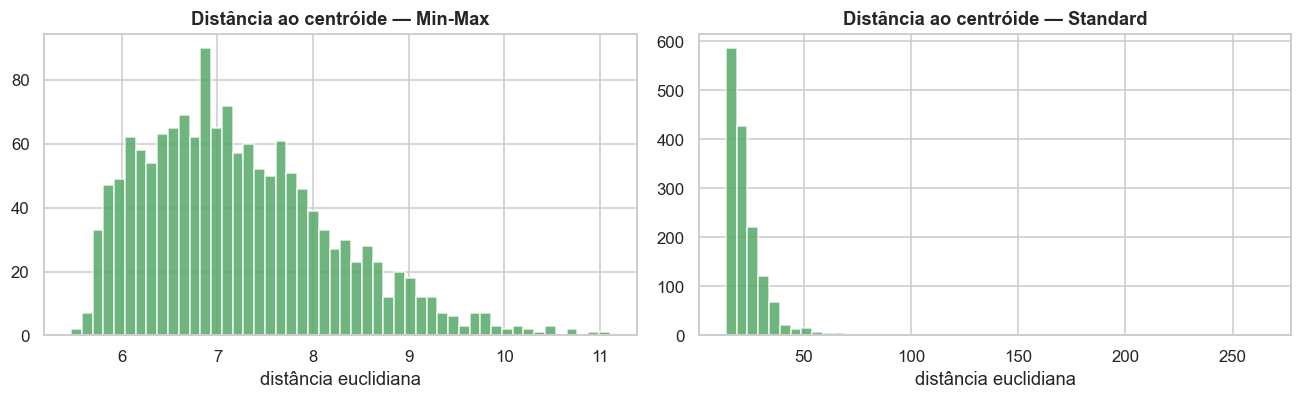

        modelo  k  silhouette    ARI   NMI
Min-Max (÷255) 10      0.0590 0.3652 0.499
StandardScaler 10      0.0016 0.3190 0.427


In [7]:
# ============================================================
# CÉLULA 18 — Comparação de representações (Min-Max vs Standard)
# ============================================================
X_minmax = X_bruto / 255.0 if X_bruto.max() > 1.5 else X_bruto.copy()
X_std = StandardScaler().fit_transform(X_bruto).astype(np.float32)

X_norm = X_minmax.copy()   # -> representação escolhida para o pipeline principal

# --- efeito na geometria: distribuição das distâncias ao centróide global ---
rng = np.random.default_rng(SEED)
sub = rng.choice(N, 1500, replace=False)

def dist_stats(X):
    Xs = X[sub]
    c = Xs.mean(axis=0)
    d = np.linalg.norm(Xs - c, axis=1)
    return float(d.mean()), float(d.std()), float(d.std() / d.mean())

m1, s1, cv1 = dist_stats(X_minmax)
m2, s2, cv2 = dist_stats(X_std)

# --- efeito no resultado de clustering (K-Means, k=N_CLASSES_REAIS) ---
linhas_repr = []
for nome, Xr in [("Min-Max (÷255)", X_minmax), ("StandardScaler", X_std)]:
    linha, lab, Xb, yb = executar_modelo(
        nome, lambda Xr=Xr: KMeans(n_clusters=N_CLASSES_REAIS, n_init=10, random_state=SEED),
        Xr, y_verdadeiro, ruido=-1)
    linhas_repr.append(linha)

df_repr = pd.DataFrame(linhas_repr)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nome, d) in zip(axes, {"Min-Max": X_minmax[sub], "Standard": X_std[sub]}.items()):
    c = d.mean(axis=0)
    ax.hist(np.linalg.norm(d - c, axis=1), bins=50, color="#55A868", alpha=0.85)
    ax.set_title(f"Distância ao centróide — {nome}")
    ax.set_xlabel("distância euclidiana")
plt.tight_layout(); plt.show()

print(df_repr[["modelo", "k", "silhouette", "ARI", "NMI"]].to_string(index=False))

In [8]:
# ============================================================
# CÉLULA 19 — 🧠 MARKDOWN DINÂMICO: qual representação venceu?
# ============================================================
r_min = df_repr.loc[df_repr["modelo"] == "Min-Max (÷255)"].iloc[0]
r_std = df_repr.loc[df_repr["modelo"] == "StandardScaler"].iloc[0]

vencedor = "Min-Max (÷255)" if r_min["ARI"] >= r_std["ARI"] else "StandardScaler"
delta_ari = abs(r_min["ARI"] - r_std["ARI"])

if delta_ari < 0.02:
    leitura = (
        f"A diferença de ARI é de apenas **{delta_ari:.3f}** — praticamente empate. "
        "Em casos assim, prefira a transformação **mais simples e mais interpretável**, "
        "que aqui é Min-Max: ela mantém a semântica de 'intensidade de pixel' e não "
        "distorce o que cada atributo significa."
    )
elif delta_ari < 0.10:
    leitura = (
        f"A diferença de ARI é de **{delta_ari:.3f}** — uma vantagem moderada para "
        f"**{vencedor}**. É o tipo de ganho que justifica adotar a transformação, "
        "mas que ainda pede validação de estabilidade antes de ir para produção."
    )
else:
    leitura = (
        f"A diferença de ARI é de **{delta_ari:.3f}** — uma vantagem **decisiva** "
        f"para **{vencedor}**. Neste caso a escolha da representação foi mais "
        "determinante que a escolha do algoritmo. Esse é o achado mais importante "
        "de toda a aula: **geometria vence algoritmo**."
    )

md(f"""
### 🔧 Leitura automática: Min-Max vs StandardScaler

| Representação | Silhouette | ARI | NMI |
|---|---|---|---|
| Min-Max (÷255) | {r_min['silhouette']:.3f} | {r_min['ARI']:.3f} | {r_min['NMI']:.3f} |
| StandardScaler | {r_std['silhouette']:.3f} | {r_std['ARI']:.3f} | {r_std['NMI']:.3f} |

**Coeficiente de variação das distâncias ao centróide**

- Min-Max: média **{m1:.2f}**, desvio **{s1:.2f}** → CV = **{cv1:.2f}**
- Standard: média **{m2:.2f}**, desvio **{s2:.2f}** → CV = **{cv2:.2f}**

Um CV baixo significa que os pontos estão **quase todos à mesma distância** do centro — exatamente
o sintoma da maldição da dimensionalidade: a noção de "perto" e "longe" se dissolve. Quanto mais
alto o CV, mais contraste geométrico o algoritmo tem para trabalhar.

**Veredito.** {leitura}

> Repare que o gráfico da esquerda (Min-Max) tem uma distribuição mais assimétrica e alongada;
> o da direita (Standard) tende a se estreitar. Estreitamento = menos sinal relativo = clusters
> mais difíceis de separar. É por isso que, em imagens, dividir por 255 costuma bater o
> StandardScaler — e agora você tem o número que comprova isso neste dataset.
""")


### 🔧 Leitura automática: Min-Max vs StandardScaler

| Representação | Silhouette | ARI | NMI |
|---|---|---|---|
| Min-Max (÷255) | 0.059 | 0.365 | 0.499 |
| StandardScaler | 0.002 | 0.319 | 0.427 |

**Coeficiente de variação das distâncias ao centróide**

- Min-Max: média **7.23**, desvio **0.98** → CV = **0.14**
- Standard: média **23.47**, desvio **12.68** → CV = **0.54**

Um CV baixo significa que os pontos estão **quase todos à mesma distância** do centro — exatamente
o sintoma da maldição da dimensionalidade: a noção de "perto" e "longe" se dissolve. Quanto mais
alto o CV, mais contraste geométrico o algoritmo tem para trabalhar.

**Veredito.** A diferença de ARI é de **0.046** — uma vantagem moderada para **Min-Max (÷255)**. É o tipo de ganho que justifica adotar a transformação, mas que ainda pede validação de estabilidade antes de ir para produção.

> Repare que o gráfico da esquerda (Min-Max) tem uma distribuição mais assimétrica e alongada;
> o da direita (Standard) tende a se estreitar. Estreitamento = menos sinal relativo = clusters
> mais difíceis de separar. É por isso que, em imagens, dividir por 255 costuma bater o
> StandardScaler — e agora você tem o número que comprova isso neste dataset.


# PARTE 4 — Redução de dimensionalidade

## 11. PCA e t-SNE

**PCA** encontra as direções (componentes) de **máxima variância** e projeta os dados nelas.
É linear, determinístico, rápido e **invertível** — o que permite reconstruir e interpretar.

A decisão central é: **quantas componentes usar?** Escolhemos o menor número que preserva
80%, 90% e 95% da variância e usamos isso como base para todo o resto.

**t-SNE** é não-linear e otimizado para *visualização* de vizinhança local. Ele revela
aglomerados que o PCA achata — mas **não é uma transformação para produção**: é caro,
não é invertível e as distâncias globais entre grupos não são interpretáveis.

> **Divisão de papéis:** PCA para *modelar e clusterizar*; t-SNE para *olhar e comunicar*.

# PCA — Análise de Componentes Principais

## 1. O que é

A **Análise de Componentes Principais** (*Principal Component Analysis*, PCA) é uma
técnica de **redução de dimensionalidade linear** que transforma um conjunto de
variáveis correlacionadas em um conjunto menor de variáveis **não correlacionadas**,
chamadas **componentes principais**, ordenadas pela quantidade de variância que
explicam.

Em uma frase: **o PCA encontra as direções em que os dados mais variam e projeta os
dados nessas direções.**

Formalmente, dado uma matriz de dados $X \in \mathbb{R}^{n \times d}$ com $n$ amostras
e $d$ features, o PCA busca uma transformação linear para um espaço de dimensão
$k < d$ que preserve o máximo possível da variância original.

> O PCA **não usa rótulos**. É aprendizado não supervisionado puro. Ele não sabe
> "o que é" cada grupo — apenas descreve a geometria dos dados.

---

## 2. A intuição geométrica (o que realmente acontece)

Imagine uma nuvem de pontos em 3D, achatada como um charuto inclinado:

1. **Primeira componente (PC1)** — é o eixo ao longo do comprimento do charuto.
   É a direção de **maior variância** dos dados. Se você tivesse que escolher uma
   única reta para representar os pontos, seria essa.
2. **Segunda componente (PC2)** — é perpendicular à primeira e aponta para a
   segunda direção de maior variância. No caso do charuto, é sua largura.
3. **Terceira componente (PC3)** — perpendicular às duas anteriores. No charuto,
   é a espessura, que é quase zero.

O PCA **gira o sistema de coordenadas** para alinhá-lo com a forma natural da nuvem
de dados. As novas coordenadas são combinações lineares das antigas.

Se a PC3 explica apenas 0,5% da variância, você pode descartá-la e representar o
charuto em 2D perdendo quase nada. **É isso que o PCA faz: descarta as direções
"finas" e mantém as "gordas".**

### Duas leituras equivalentes do mesmo método

- **Maximizar variância:** a primeira componente é a direção $w$ que maximiza
  $\text{Var}(Xw)$, sujeita a $\|w\| = 1$.
- **Minimizar erro de reconstrução:** a primeira componente é a reta que minimiza a
  soma dos quadrados das distâncias dos pontos até ela (o "erro de projeção").

Matematicamente, as duas formulações têm **a mesma solução**. Isso é uma
propriedade elegante: preservar a variância é o mesmo que perder o mínimo de
informação geométrica.

---

## 3. A matemática (sem mistério)

### 3.1 Passo 1 — Centralizar os dados

O PCA exige que os dados tenham média zero. Caso contrário, a "direção de maior
variância" seria simplesmente a direção que aponta do zero até a média dos dados —
um artefato, não estrutura.

$X_c = X - \bar{X}$

onde $\bar{X}$ é o vetor de médias de cada feature.

### 3.2 Passo 2 — A matriz de covariância

A covariância captura como duas features variam juntas:

$\Sigma = \frac{1}{n-1} X_c^\top X_c$

A matriz $\Sigma$ é $d \times d$, simétrica e positiva semidefinida. A diagonal
contém as variâncias de cada feature; fora da diagonal, as covariâncias entre pares.

### 3.3 Passo 3 — Autovalores e autovetores

Decompomos a matriz de covariância:

$\Sigma v_i = \lambda_i v_i$

- **Autovetores** $v_i$ → as **direções** das componentes principais.
- **Autovalores** $\lambda_i$ → a **quantidade de variância** explicada por cada
  direção.

Ordenando os autovalores em ordem decrescente ($\lambda_1 \geq \lambda_2 \geq \dots
\geq \lambda_d$), os autovetores correspondentes são as componentes, da mais
informativa para a menos.

> Autovetores de uma matriz simétrica são **ortogonais entre si**. É por isso que
> as componentes principais são sempre **não correlacionadas** — o PCA diagonaliza
> a estrutura de covariância.

### 3.4 Passo 4 — Projetar os dados

Para reduzir de $d$ para $k$ dimensões, montamos a matriz $W_k$ com os $k$ primeiros
autovetores como colunas e projetamos:

$Z = X_c W_k$

O resultado $Z \in \mathbb{R}^{n \times k}$ é o conjunto de dados transformado.

### 3.5 A variância explicada

A fração de variância explicada pela componente $i$ é simplesmente:

$\text{VE}_i = \frac{\lambda_i}{\sum_{j=1}^{d} \lambda_j}$

E a variância acumulada nas primeiras $k$ componentes:

$\text{VE acumulada}(k) = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{j=1}^{d} \lambda_j}$

Essa é a métrica que você usa para decidir quantas componentes manter.

### 3.6 SVD — como é calculado na prática

Ninguém calcula a matriz de covariância e a decompõe em produção: é numericamente
instável e lento. A implementação real usa **Decomposição em Valores Singulares**
(SVD) da matriz centralizada:

$X_c = U S V^\top$

Os autovetores de $\Sigma$ são as colunas de $V$, e os autovalores são
$\lambda_i = s_i^2 / (n-1)$. O resultado é o mesmo, mas com estabilidade numérica
muito superior — e é exatamente o que o `sklearn` e o `numpy` fazem por baixo.

---

## 4. Para que serve — os seis usos reais

### 4.1 Redução de dimensionalidade

O uso central. Passar de 500 features para 30 componentes pode reduzir tempo de
treino em ordens de magnitude com perda mínima de informação. É a aplicação mais
comum em pipelines de machine learning com muitas variáveis correlacionadas.

### 4.2 Visualização de dados de alta dimensão

Não é possível desenhar 64 dimensões. Projetar em 2D com PCA é a forma mais rápida
de ter um primeiro olhar sobre a estrutura dos dados. A projeção é **linear**, então
o que aparece no gráfico é uma visão parcial — mas honesta — da geometria real.

> Para visualização, o t-SNE e o UMAP costumam separar melhor os grupos. A vantagem
> do PCA aqui é ser instantâneo, determinístico e reprodutível.

### 4.3 Remoção de ruído

As últimas componentes tendem a capturar quase só ruído (variância aleatória de
baixa amplitude). Descartá-las é uma forma de **filtro**: você reconstrói os dados
usando apenas as $k$ primeiras componentes e obtém uma versão suavizada da realidade.

$X_{\text{reconstruído}} = Z W_k^\top + \bar{X}$

### 4.4 Descorrelação (pré-processamento)

Modelos como regressão linear múltipla sofrem com **multicolinearidade** — features
muito correlacionadas tornam os coeficientes instáveis. Como as componentes do PCA
são ortogonais por construção, usar $Z$ em vez de $X$ elimina esse problema
estruturalmente.

### 4.5 Aceleração de clusterização e KNN

Algoritmos baseados em distância se degradam em alta dimensionalidade (*maldição da
dimensionalidade*: as distâncias tendem a se uniformizar). Reduzir com PCA antes de
rodar K-Means, DBSCAN ou KNN melhora tanto a velocidade quanto a qualidade do
resultado. É a combinação que usamos no notebook de aprendizado não supervisionado.

### 4.6 Compressão e extração de features

Em imagens, sinais e séries temporais, o PCA funciona como um codec linear: guarda
$k$ coeficientes por amostra em vez de $d$ valores brutos. Em *eigenfaces*, rostos
são representados por dezenas de componentes em vez de milhares de pixels.

---

## 5. Como escolher o número de componentes

Não existe regra universal, mas existem quatro critérios objetivos:

| Critério | Regra prática | Quando usar |
|---|---|---|
| **Variância acumulada** | Manter 90–95% | Padrão de mercado para pré-processamento |
| **Kaiser** | Manter componentes com $\lambda_i > 1$ (dados padronizados) | Quando as features estão em escala comparável |
| **Scree plot** | Cortar no "cotovelo" da curva de autovalores | Análise exploratória |
| **Validação a jusante** | Otimizar a métrica do modelo final | Quando o PCA é etapa de um pipeline supervisionado |

> **Regra de ouro:** o número de componentes não é um fim em si. Se o objetivo é
> visualizar, use 2. Se o objetivo é alimentar um modelo, escolha $k$ pela métrica
> final, não pela variância.

---

## 6. Limitações — o que você precisa saber antes de usar

**a) É estritamente linear.** O PCA só encontra estruturas planas. Se os dados
formam uma variedade curva (um "S" em 3D, uma circunferência), a projeção linear
vai destruir a estrutura. Para isso existem t-SNE, UMAP, Isomap, autoencoders.

**b) Assume que variância = informação.** O PCA trata direções de alta variância
como importantes. Mas uma feature pode ter variância enorme e ser **puro ruído**
(ex.: um sensor descalibrado). Nesse caso, o PCA vai dar a ela a primeira componente.
Sempre inspecione os dados antes.

**c) É sensível à escala.** Uma feature em reais (milhares) e outra em porcentagem
(0–100) fazem o PCA apontar quase inteiramente para a primeira. **Padronize com
`StandardScaler` antes** — a menos que você queira deliberadamente preservar as
escalas originais.

**d) É sensível a outliers.** A média e a variância são estatísticas não robustas.
Um único ponto extremo pode girar toda a primeira componente. Alternativas:
`RobustScaler`, ou remoção de outliers antes do ajuste.

**e) As componentes perdem interpretabilidade.** PC1 é uma combinação linear de
todas as features originais com coeficientes arbitrários. Dizer "PC1 representa
'saúde financeira'" exige análise dos *loadings* e é sempre uma interpretação
humana, nunca um fato do método.

**f) Componentes não são features.** Você não pode dizer "o cliente tem PC2 = 3,4".
As componentes vivem em um espaço abstrato construído para maximizar variância.

---

## 7. PCA vs. as alternativas

| Método | Tipo | Preserva | Velocidade | Uso típico |
|---|---|---|---|---|
| **PCA** | Linear | Variância global | Muito rápido | Pré-processamento, compressão |
| **t-SNE** | Não linear | Vizinhança local | Lento | Visualização 2D |
| **UMAP** | Não linear | Estrutura local + global | Rápido | Visualização e features |
| **Autoencoder** | Não linear | Reconstrução | Depende de GPU | Alta dimensionalidade complexa |
| **ICA** | Linear | Independência estatística | Rápido | Separação de sinais (áudio, EEG) |
| **LDA** | Linear supervisionado | Separabilidade entre classes | Rápido | Redução com rótulos disponíveis |
| **TruncatedSVD** | Linear | Variância em matrizes esparsas | Rápido | Texto (TF-IDF), dados esparsos |

**Regra de decisão:** comece sempre pelo PCA. É rápido, determinístico, barato e
resolve a maioria dos casos. Só migre para métodos não lineares quando o PCA
visivelmente falhar em preservar a estrutura — e saiba que essa migração custa
tempo, hiperparâmetros e reprodutibilidade.

---

## 8. Implementação prática

```python
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Padronizar (obrigatório)
X_std = StandardScaler().fit_transform(X)

# 2. Ajustar com todas as componentes para inspecionar a variância
pca_full = PCA(random_state=42).fit(X_std)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

n90 = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes para 90% da variância: {n90} de {X.shape[1]}")

# 3. Reduzir de fato
pca = PCA(n_components=n90, random_state=42)
X_pca = pca.fit_transform(X_std)

# 4. Reconstruir (útil para medir perda e filtrar ruído)
X_rec = pca.inverse_transform(X_pca)

print(f"Shape original     : {X_std.shape}")
print(f"Shape reduzido     : {X_pca.shape}")
print(f"Variância retida   : {var_acum[n90-1]:.1%}")
print(f"Erro de reconstrução (MSE): {np.mean((X_rec - X_std)**2):.5f}")
```

### Verificação manual (para entender o que o `sklearn` faz)

```python
Xc = X_std - X_std.mean(axis=0)                       # centralizar
cov = np.cov(Xc, rowvar=False)                        # matriz de covariância
lambdas, V = np.linalg.eigh(cov)                      # autovalores/autovetores

idx = np.argsort(lambdas)[::-1]                       # ordem decrescente
lambdas, V = lambdas[idx], V[:, idx]

Z = Xc @ V[:, :n90]                                   # projeção
print(f"Variância explicada por PC1: {lambdas[0]/lambdas.sum():.2%}")
```

> **Nota:** os autovetores podem sair com sinal invertido entre implementações.
> Isso é irrelevante — a direção é a mesma, só o sentido do eixo muda. Por isso a
> comparação usa `np.abs`.

---

## 9. Checklist de uso correto

- [ ] Centralizei os dados? (o `sklearn` já faz isso internamente)
- [ ] Padronizei a escala com `StandardScaler`?
- [ ] Verifiquei outliers que possam distorcer a variância?
- [ ] Inspecionei a curva de variância acumulada antes de escolher $k$?
- [ ] `fit` foi chamado **apenas no treino** e `transform` no teste? (evitar *leakage*)
- [ ] Se o objetivo é visualizar, usei 2 componentes e sei que a projeção é parcial?
- [ ] Se as componentes alimentam um modelo, validei que a performance não caiu?
- [ ] Documentei quantas features existiam e quantas componentes ficaram?

---

## 10. Resumo em cinco linhas

1. O PCA **gira os eixos** dos dados para alinhá-los com as direções de maior variância.
2. É uma transformação **linear, não supervisionada**, calculada por autovetores da
   matriz de covariância (na prática, por SVD).
3. Serve para **reduzir dimensionalidade, visualizar, filtrar ruído, descorrelacionar
   features e acelerar algoritmos baseados em distância**.
4. Exige **padronização** e é **sensível a outliers**; só captura estrutura **linear**.
5. É sempre o **primeiro método a tentar** — barato, determinístico e resolve a
   maioria dos casos. Métodos não lineares só quando ele falha claramente.

# t-SNE — Incorporação Estocástica de Vizinhos com t-Distribuição

## 1. O que é

O **t-SNE** (*t-Distributed Stochastic Neighbor Embedding*) é uma técnica de **redução de
dimensionalidade não linear**, projetada especificamente para **visualização** de dados de alta
dimensão em 2 ou 3 dimensões.

Diferente do PCA, que busca preservar a **variância global**, o t-SNE busca preservar a
**vizinhança local**: pontos que estão próximos no espaço original devem continuar próximos no
plano. Ele não tenta representar distâncias entre grupos distantes — e é por isso que seus mapas
são tão legíveis e tão mal interpretados.

> O t-SNE **não usa rótulos**. É aprendizado não supervisionado puro. Ele não sabe "o que é"
> cada grupo — apenas organiza os pontos segundo proximidade.
>
> E, ao contrário do PCA, o t-SNE **não é uma transformação**: é um mapa. Não existe
> `transform()` para dados novos.

---

## 2. A intuição geométrica

Imagine que os dados vivem em 784 dimensões, mas apenas algumas dezenas de "direções" carregam
informação real. As demais são ruído.

O t-SNE trabalha em três movimentos:

1. **No espaço original**, cada ponto ganha uma distribuição de probabilidade sobre os demais,
   centrada em si e calibrada de modo que tenha exatamente a **perplexidade** desejada de vizinhos
   efetivos. Perto = probabilidade alta; longe = probabilidade quase nula.
2. **No plano 2D**, faz-se o mesmo, mas com uma distribuição de **caudas pesadas** (t-Student).
3. **A otimização** ajusta as posições no plano até que as duas matrizes de probabilidade fiquem
   o mais parecidas possível.

O resultado é um mapa onde ilhas visuais correspondem a grupos de pontos mutuamente próximos no
espaço original.

### O problema que a cauda pesada resolve (crowding problem)

Ao projetar 784 dimensões em 2, não há espaço para preservar todas as distâncias. Em um plano, o
número de pontos que cabem a uma distância $r$ cresce com $r$, enquanto em 784 dimensões cresce
com $r^{784}$. A consequência é que **pontos moderadamente distantes colapsam uns sobre os
outros**.

A distribuição t-Student, com cauda longa, permite que pontos moderadamente distantes fiquem
repelidos para longe no plano sem custo de verossimilhança alto. É daí que vem a aparência
característica do t-SNE: **aglomerados bem separados com espaço vazio entre eles**.

---

## 3. A matemática (sem mistério)

### 3.1 Passo 1 — Similaridade no espaço original

Para cada par de pontos, define-se a probabilidade condicional de $j$ ser vizinho de $i$:

$p_{j|i} = \frac{\exp\left(-\|x_i - x_j\|^2 / 2\sigma_i^2\right)}{\sum_{k \neq i}\exp\left(-\|x_i - x_k\|^2 / 2\sigma_i^2\right)}$

O parâmetro $\sigma_i$ é **próprio de cada ponto** — pontos em regiões densas recebem $\sigma$
pequeno, pontos em regiões esparsas recebem $\sigma$ grande. Isso é o que torna o método adaptativo
à densidade local.

Em seguida, simetriza-se:

$p_{ij} = \frac{p_{j|i} + p_{i|j}}{2n}$

A simetrização garante que a matriz seja bem definida e melhora a estabilidade da otimização.

### 3.2 Passo 2 — A perplexidade

A perplexidade é um alvo de **entropia**, não um número de vizinhos:

$\text{Perp}(P_i) = 2^{H(P_i)} \quad \text{onde} \quad H(P_i) = -\sum_j p_{j|i}\log_2 p_{j|i}$

Na prática, o algoritmo faz **busca binária em $\sigma_i$** até que a perplexidade de cada ponto
atinja o valor desejado. Interpretação prática: perplexidade ≈ *quantos vizinhos efetivos cada
ponto considera*. Valores usuais: 5 a 50.

### 3.3 Passo 3 — Similaridade no plano

No espaço de saída usa-se uma **t-Student com 1 grau de liberdade** (cauda pesada):

$q_{ij} = \frac{\left(1 + \|y_i - y_j\|^2\right)^{-1}}{\sum_{k \neq l}\left(1 + \|y_k - y_l\|^2\right)^{-1}}$

O expoente $-1$ é o coração do método: ele confere a cauda longa que alivia o *crowding*.

### 3.4 Passo 4 — Divergência KL

A função objetivo mede o quanto a distribuição no plano se afasta da original:

$C = KL(P \,\|\, Q) = \sum_{i \neq j} p_{ij}\log\frac{p_{ij}}{q_{ij}}$

A KL é **assimétrica**, e essa assimetria é intencional: usar $p$ como referência penaliza
fortemente colocar dois pontos próximos no original longe no plano (falso afastamento), mas
penaliza pouco o contrário. O t-SNE prefere **agrupar demais** a **separar demais**.

### 3.5 Passo 5 — Gradiente

O gradiente da KL tem forma fechada e elegante:

$\frac{\partial C}{\partial y_i} = 4\sum_j (p_{ij} - q_{ij})\left(1 + \|y_i - y_j\|^2\right)^{-1}(y_i - y_j)$

Interpretação: se $p_{ij} > q_{ij}$ (deveriam estar mais perto no plano), o gradiente **atrai**;
se $p_{ij} < q_{ij}$, **repele**. Somado a momento e a uma taxa de aprendizado adaptativa, é o que
move as posições até o mapa estabilizar.

---

## 4. Para que serve

### 4.1 Visualização — o uso central
É para isso que o método foi desenhado. Projetar dados de centenas de dimensões em 2D para
inspeção visual, identificação de agrupamentos e detecção de estrutura insuspeita.

### 4.2 Diagnóstico de separabilidade
Antes de investir em clusterização, responder: *existe estrutura separável nos dados?* Se o mapa
mostra ilhas nítidas, há sinal. Se mostra uma mancha contínua, nenhum algoritmo vai inventar
separação que não existe.

### 4.3 Auditoria de representação
Comparar embeddings diferentes (PCA, autoencoder, features de um classificador) rodando t-SNE em
cada um e verificando qual produz separação mais coerente.

### 4.4 Detecção de padrões e outliers
Pontos isolados no mapa frequentemente correspondem a outliers reais — ou a erros de
pré-processamento, o que é igualmente útil.

> **O que o t-SNE NÃO serve para fazer:** alimentar um modelo, servir de feature para outro
> algoritmo, ou quantificar similaridade. Ele não tem `transform()`, não é determinístico e não
> é reproduzível entre versões.

---

## 5. Como escolher a perplexidade

Não existe valor universal, mas existe comportamento previsível:

| Perplexidade | Comportamento | Quando usar |
|---|---|---|
| 2 – 5 | foco quase individual; fragmenta grupos reais em várias ilhas | raramente, só para inspeção local |
| 5 – 15 | estrutura local detalhada, mais fragmentação | dados pequenos ou muito heterogêneos |
| **30** | **padrão do sklearn — bom equilíbrio** | **ponto de partida** |
| 50 – 100 | estrutura mais global, grupos se fundem | n grande (dezenas de milhares) |

**Prática recomendada:** testar 5, 30 e 50 e verificar se a conclusão principal se mantém. Se o
mapa muda radicalmente com a perplexidade, a estrutura é ambígua — e isso é a informação mais
valiosa do experimento.

Regra de bolso: perplexidade deve ser menor que $n/3$, preferencialmente na faixa de $5$ a
$\sqrt{n}$.

---

## 6. Limitações — o que você precisa saber antes de usar

**a) Distâncias entre grupos não significam nada.** Duas ilhas próximas não são grupos similares.
O algoritmo só preserva vizinhança local.

**b) O tamanho da ilha não é o tamanho do grupo.** O t-SNE não preserva densidade absoluta.
Um grupo de 500 pontos pode ocupar menos área que um de 50.

**c) Não é determinístico.** Sementes diferentes produzem mapas diferentes — mesma estrutura
global, posições e rotações distintas. Sempre fixe `random_state` em relatório.

**d) Não generaliza para dados novos.** Não existe `transform()`. Novo ponto exige reexecutar o
algoritmo inteiro (ou usar aproximações como o `openTSNE` com `transform` por interpolização).

**e) Não é invertível.** Você não consegue voltar do plano para o espaço original. Não serve para
reconstrução nem para filtragem de ruído.

**f) Custo quadrático.** A versão clássica é $O(n^2)$ em tempo e memória. Acima de ~10.000 pontos
usa-se Barnes-Hut ($O(n\log n)$) ou FIt-SNE ($O(n)$).

**g) Estrutura aparente pode ser artefato.** O t-SNE tende a produzir aglomerados mesmo em dados
uniformes — o algoritmo impõe estrutura onde não há. Sempre valide visualmente o resultado contra o
espaço original.

**h) Não é pré-processamento.** Aplicar t-SNE antes de K-Means é erro metodológico: você estaria
clusterizando artefatos do mapa, não estrutura dos dados.

---

## 7. t-SNE vs. as alternativas

| Método | Tipo | Preserva | Velocidade | Uso típico |
|---|---|---|---|---|
| **PCA** | Linear | Variância global | Muito rápido | Pré-processamento, compressão |
| **t-SNE** | Não linear | Vizinhança local | Lento | Visualização 2D |
| **UMAP** | Não linear | Estrutura local + global | Rápido | Visualização e features |
| **Autoencoder** | Não linear | Reconstrução | GPU | Alta dimensionalidade complexa |
| **Isomap** | Não linear (geodésico) | Distância ao longo da variedade | Médio | Variedades curvas |
| **PaCMAP** | Não linear | Local + global, com `transform` | Rápido | Alternativa moderna ao t-SNE |

**Divisão de papéis no pipeline:** PCA ou autoencoder **modelam**; t-SNE **comunica**. O t-SNE entra
depois da redução linear (sobre as componentes do PCA, não sobre os pixels crus) — rodá-lo em
centenas de dimensões é proibitivamente lento e degrada a qualidade.

---

## 8. Implementação prática

```python
import numpy as np
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

# 1. Reduzir antes com PCA (obrigatório na prática)
X_pca = PCA(n_components=50, random_state=42).fit_transform(X_std / 255.0)

# 2. t-SNE — init='pca' acelera convergência e preserva a estrutura global
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",              # melhor que 'random'
    learning_rate="auto",    # = max(n/early_exaggeration/4, 50)
    n_iter=1000,
    random_state=42,
)
X_tsne = tsne.fit_transform(X_pca)

print(f"KL final: {tsne.kl_divergence_:.4f}")

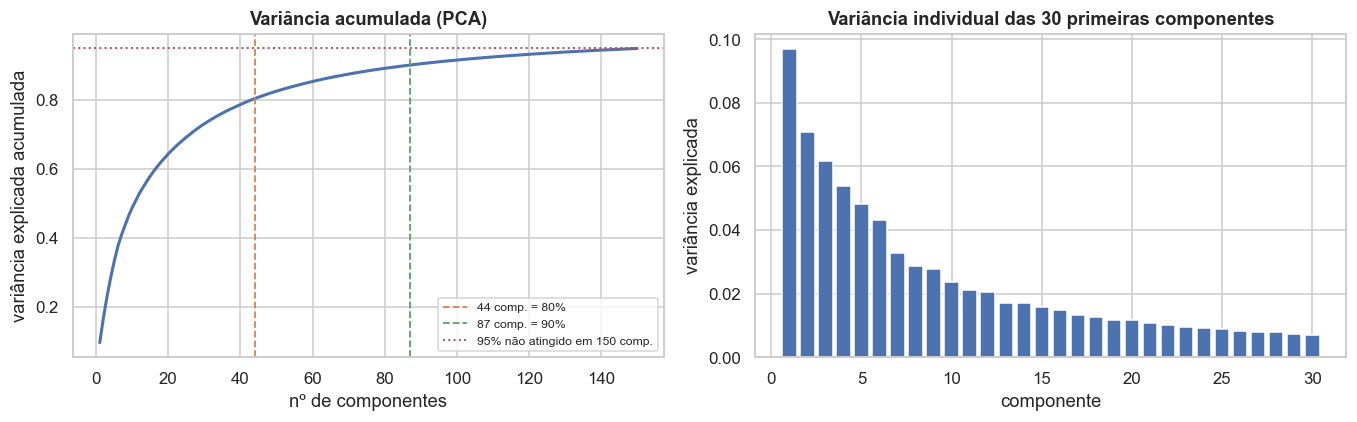

80% de variância: 44 componentes
90% de variância: 87 componentes  <-- usado no pipeline
95% de variância: não atingido em 150 (máx 94.8%)
Redução: 784 -> 87 dimensões (88.9% de compressão)


In [9]:
# ============================================================
# CÉLULA 21 — PCA: variância explicada e escolha de componentes
# ============================================================
N_COMP_MAX = min(150, N_FEATURES)
pca_full = PCA(n_components=N_COMP_MAX, random_state=SEED).fit(X_norm)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)


def componentes_para(var_acum, limiar):
    """Menor nº de componentes que atinge `limiar`.
    Devolve None quando o limiar não é alcançado na faixa calculada."""
    acima = np.flatnonzero(var_acum >= limiar)
    return int(acima[0] + 1) if acima.size else None


k80 = componentes_para(var_acum, 0.80)
k90 = componentes_para(var_acum, 0.90)
k95 = componentes_para(var_acum, 0.95)

N_PCA = k90   # componentes usadas no pipeline de clusterização
X_pca = PCA(n_components=N_PCA, random_state=SEED).fit_transform(X_norm).astype(np.float32)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))

axes[0].plot(range(1, N_COMP_MAX + 1), var_acum, color="#4C72B0", lw=2)
for k, cor, limiar in [(k80, "#DD8452", 0.80), (k90, "#55A868", 0.90), (k95, "#C44E52", 0.95)]:
    if k is None:                                  # limiar não atingido -> linha horizontal
        axes[0].axhline(limiar, color=cor, ls=":", lw=1.3,
                        label=f"{limiar:.0%} não atingido em {N_COMP_MAX} comp.")
    else:
        axes[0].axvline(k, color=cor, ls="--", lw=1.2,
                        label=f"{k} comp. = {var_acum[k-1]:.0%}")
axes[0].set_title("Variância acumulada (PCA)")
axes[0].set_xlabel("nº de componentes")
axes[0].set_ylabel("variância explicada acumulada")
axes[0].legend(loc="lower right", fontsize=8)

n_barras = min(30, N_COMP_MAX)
axes[1].bar(range(1, n_barras + 1), pca_full.explained_variance_ratio_[:n_barras], color="#4C72B0")
axes[1].set_title(f"Variância individual das {n_barras} primeiras componentes")
axes[1].set_xlabel("componente")
axes[1].set_ylabel("variância explicada")

plt.tight_layout(); plt.show()

def fmt(k, limiar):
    return f"{k} componentes" if k is not None else f"não atingido em {N_COMP_MAX} (máx {var_acum[-1]:.1%})"

print(f"80% de variância: {fmt(k80, 0.80)}")
print(f"90% de variância: {fmt(k90, 0.90)}  <-- usado no pipeline")
print(f"95% de variância: {fmt(k95, 0.95)}")
print(f"Redução: {N_FEATURES} -> {N_PCA} dimensões ({100*(1-N_PCA/N_FEATURES):.1f}% de compressão)")

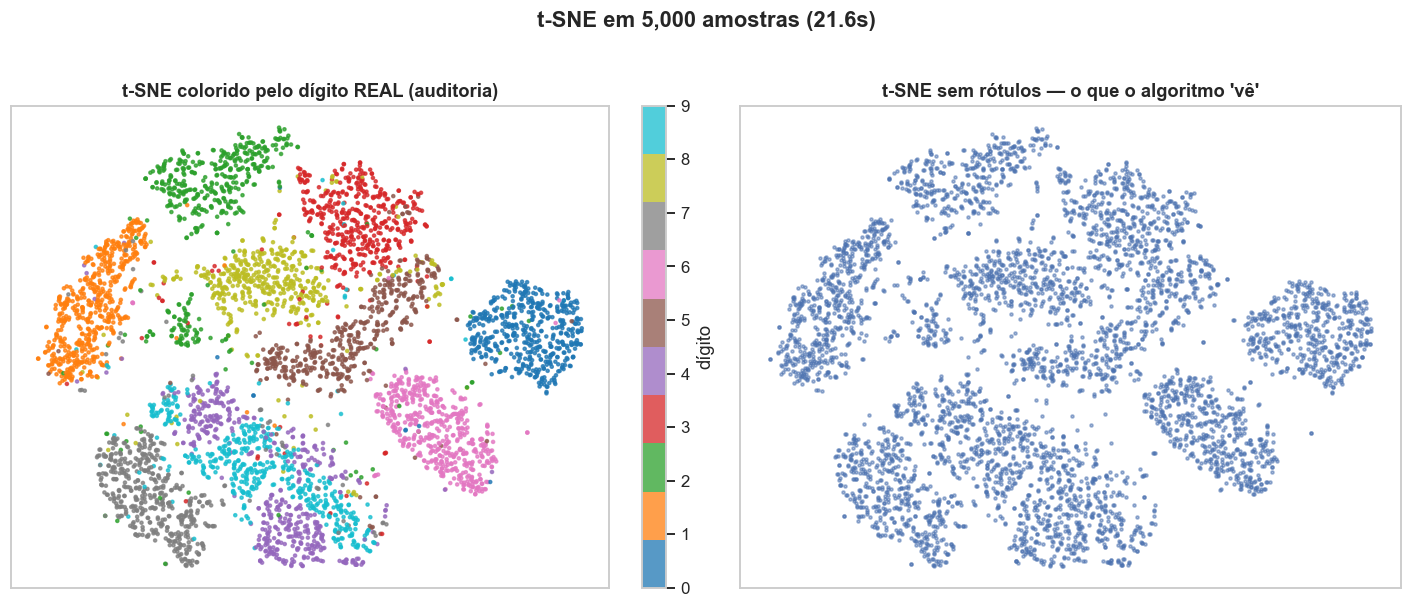

In [10]:
# ============================================================
# CÉLULA 22 — t-SNE para visualização (subamostra por custo O(n²))
# ============================================================
from sklearn.manifold import TSNE

N_TSNE = min(5000, N)
idx_tsne = np.random.default_rng(SEED).choice(N, N_TSNE, replace=False)

t0 = time.perf_counter()
X_tsne = TSNE(n_components=2, perplexity=30, init="pca",
              learning_rate="auto", random_state=SEED).fit_transform(X_pca[idx_tsne])
T_TEMPO_TSNE = time.perf_counter() - t0

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))

sc = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_verdadeiro[idx_tsne],
                     cmap="tab10", s=4, alpha=0.75)
axes[0].set_title("t-SNE colorido pelo dígito REAL (auditoria)")
axes[0].set_xticks([]); axes[0].set_yticks([])
plt.colorbar(sc, ax=axes[0], fraction=0.046, label="dígito")

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], s=4, alpha=0.5, color="#4C72B0")
axes[1].set_title("t-SNE sem rótulos — o que o algoritmo 'vê'")
axes[1].set_xticks([]); axes[1].set_yticks([])

plt.suptitle(f"t-SNE em {N_TSNE:,} amostras ({T_TEMPO_TSNE:.1f}s)", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

In [11]:
# ============================================================
# CÉLULA 23 — 🧠 MARKDOWN DINÂMICO: leitura do PCA e do t-SNE
# ============================================================
v1      = pca_full.explained_variance_ratio_[0]
v10     = pca_full.explained_variance_ratio_[:10].sum()
var_max = float(var_acum[-1])       # variância máxima alcançada na faixa calculada

# --- guarda: se 90% não foi atingido, a célula 21 já teria falhado; mas proteja-se ---
if N_PCA is None:
    raise ValueError(
        f"90% da variância não foi atingido em {N_COMP_MAX} componentes "
        f"(máximo: {var_max:.1%}). Defina N_PCA manualmente na célula 21."
    )


def linha_meta(limiar, k):
    """Linha da tabela que sobrevive a k=None (limiar não atingido)."""
    if k is None:
        return (f"| {limiar:.0%} | — | — | **não atingido** "
                f"(máx. {var_max:.1%} em {N_COMP_MAX} comp.) |")
    return f"| {limiar:.0%} | {k} | {100*k/N_FEATURES:.1f}% | {var_acum[k-1]:.1%} |"


# --- vereditos de compressão ---
razao = N_PCA / N_FEATURES

if razao < 0.10:
    veredito_compressao = (
        f"**Compressão brutal e barata.** {N_PCA} componentes substituem {N_FEATURES} atributos "
        f"({100*razao:.1f}% do tamanho original) preservando 90% da variância. "
        "Isso corta custo computacional de forma dramática — DBSCAN, Spectral e t-SNE, que "
        "são inviáveis em alta dimensão, passam a ser executáveis."
    )
elif razao < 0.35:
    veredito_compressao = (
        f"**Compressão relevante.** {N_PCA} de {N_FEATURES} atributos preservam 90% da variância "
        f"({100*razao:.1f}% das dimensões originais). Ganho sólido de velocidade com "
        "perda controlada de informação."
    )
else:
    veredito_compressao = (
        f"**A informação é difusa.** São necessárias {N_PCA} componentes ({100*razao:.1f}% "
        "das dimensões) para chegar a 90% da variância — sinal de que a estrutura não está "
        "concentrada em poucas direções. O PCA ajuda menos aqui do que em dados tabulares típicos."
    )

# --- veredito da PC1 ---
if v1 > 0.25:
    veredito_pc1 = (
        f"A **primeira componente sozinha explica {v1:.1%}** da variância — há uma direção "
        "dominante muito forte. Provavelmente essa componente está capturando algo global, "
        "como a quantidade total de tinta na imagem."
    )
else:
    veredito_pc1 = (
        f"A **primeira componente explica {v1:.1%}** — não existe uma direção dominante única. "
        f"As 10 primeiras componentes somam {v10:.1%}. A estrutura é distribuída entre várias "
        "direções ortogonais, o que é típico de dados complexos e sugere que um modelo não linear "
        "(autoencoder) pode capturar mais que o PCA."
    )

# --- nota sobre o limiar de 95% não atingido ---
if k95 is None:
    nota_95 = (
        f"\n> ⚠️ **95% da variância não é alcançado com {N_COMP_MAX} componentes** — o teto é "
        f"{var_max:.1%}. Isso não é defeito do código: a variância dos pixels é distribuída por "
        f"centenas de direções fracamente correlacionadas. Se precisar do patamar de 95%, recalcule "
        f"o `pca_full` com `n_components=None` (espectro completo) ou use "
        f"`svd_solver='randomized'` com um `N_COMP_MAX` maior.\n"
    )
else:
    nota_95 = f"\n> 95% da variância é alcançado em **{k95} componentes** ({100*k95/N_FEATURES:.1f}% das dimensões).\n"

# --- render ---
md(f"""
### 📉 Leitura automática da redução de dimensionalidade

**PCA — quanto de informação cabe em quanto espaço**

| Meta | Componentes | % das dimensões originais | Variância preservada |
|---|---|---|---|
{linha_meta(0.80, k80)}
{linha_meta(0.90, k90)}
{linha_meta(0.95, k95)}
{nota_95}
{veredito_compressao}

{veredito_pc1}

**Como ler o gráfico de barras.** A queda abrupta nas primeiras componentes e a cauda longa
depois confirmam o que o mapa de variância já indicava: existe **sinal concentrado** e muito
**ruído fino** espalhado. A cauda longa é o que descartamos — e descartar ruído é justamente
o que melhora a clusterização. O fato de {N_COMP_MAX} componentes não bastarem para 95% é a
prova numérica dessa cauda: cada componente adicional contribui com frações pequenas e
persistentes de variância, sem nunca desaparecer completamente.

**t-SNE — o que o gráfico revela**

- **Painel esquerdo (colorido pelo dígito real):** este é o painel de *auditoria*. Ele mostra se
  a estrutura que o algoritmo enxerga realmente corresponde aos grupos naturais dos dados.
  Ilhas bem definidas e homogêneas = o sinal existe e é recuperável.
- **Painel direito (sem rótulos):** é o **input que a clusterização recebe**. Nenhum algoritmo
  vê cores — ele vê apenas essas posições. A pergunta de toda a aula é: *consigo reconstruir
  as ilhas do painel esquerdo usando só o painel direito?*

**Duas ressalvas honestas sobre o t-SNE**

1. O tamanho relativo das ilhas **não** representa o tamanho real dos grupos.
2. A distância entre ilhas **não** é uma medida de dissimilaridade confiável. O t-SNE preserva
   vizinhança local, não geometria global.

Por isso o t-SNE fica no diagnóstico, e o PCA (ou os embeddings do autoencoder) fica no modelo.
""")


### 📉 Leitura automática da redução de dimensionalidade

**PCA — quanto de informação cabe em quanto espaço**

| Meta | Componentes | % das dimensões originais | Variância preservada |
|---|---|---|---|
| 80% | 44 | 5.6% | 80.3% |
| 90% | 87 | 11.1% | 90.0% |
| 95% | — | — | **não atingido** (máx. 94.8% em 150 comp.) |

> ⚠️ **95% da variância não é alcançado com 150 componentes** — o teto é 94.8%. Isso não é defeito do código: a variância dos pixels é distribuída por centenas de direções fracamente correlacionadas. Se precisar do patamar de 95%, recalcule o `pca_full` com `n_components=None` (espectro completo) ou use `svd_solver='randomized'` com um `N_COMP_MAX` maior.

**Compressão relevante.** 87 de 784 atributos preservam 90% da variância (11.1% das dimensões originais). Ganho sólido de velocidade com perda controlada de informação.

A **primeira componente explica 9.7%** — não existe uma direção dominante única. As 10 primeiras componentes somam 48.8%. A estrutura é distribuída entre várias direções ortogonais, o que é típico de dados complexos e sugere que um modelo não linear (autoencoder) pode capturar mais que o PCA.

**Como ler o gráfico de barras.** A queda abrupta nas primeiras componentes e a cauda longa
depois confirmam o que o mapa de variância já indicava: existe **sinal concentrado** e muito
**ruído fino** espalhado. A cauda longa é o que descartamos — e descartar ruído é justamente
o que melhora a clusterização. O fato de 150 componentes não bastarem para 95% é a
prova numérica dessa cauda: cada componente adicional contribui com frações pequenas e
persistentes de variância, sem nunca desaparecer completamente.

**t-SNE — o que o gráfico revela**

- **Painel esquerdo (colorido pelo dígito real):** este é o painel de *auditoria*. Ele mostra se
  a estrutura que o algoritmo enxerga realmente corresponde aos grupos naturais dos dados.
  Ilhas bem definidas e homogêneas = o sinal existe e é recuperável.
- **Painel direito (sem rótulos):** é o **input que a clusterização recebe**. Nenhum algoritmo
  vê cores — ele vê apenas essas posições. A pergunta de toda a aula é: *consigo reconstruir
  as ilhas do painel esquerdo usando só o painel direito?*

**Duas ressalvas honestas sobre o t-SNE**

1. O tamanho relativo das ilhas **não** representa o tamanho real dos grupos.
2. A distância entre ilhas **não** é uma medida de dissimilaridade confiável. O t-SNE preserva
   vizinhança local, não geometria global.

Por isso o t-SNE fica no diagnóstico, e o PCA (ou os embeddings do autoencoder) fica no modelo.


# PARTE 5 — Baseline: K-Means

## 12. Como o K-Means funciona

1. Escolhe $k$ centróides iniciais (k-means++ escolhe pontos bem espalhados, reduzindo variância).
2. **Atribuição:** cada ponto vai para o centróide mais próximo.
3. **Atualização:** cada centróide vira a média dos pontos atribuídos a ele.
4. Repete 2–3 até convergir (sem mudança de atribuição ou limite de iterações).

**Complexidade:** $O(n \cdot k \cdot p \cdot i)$ — linear em $n$, extremamente rápido.
**Garantia:** converge para um **mínimo local** — não global. Daí a necessidade de múltiplas inicializações (`n_init`).
**Premissas embutidas:** clusters convexos, esféricos, de variância similar, separáveis por hiperplanos. Se a forma real dos dados for outra, o K-Means vai mentir com confiança.

Vamos escolher $k$ variando de 2 a 15 e medindo três critérios ao mesmo tempo.

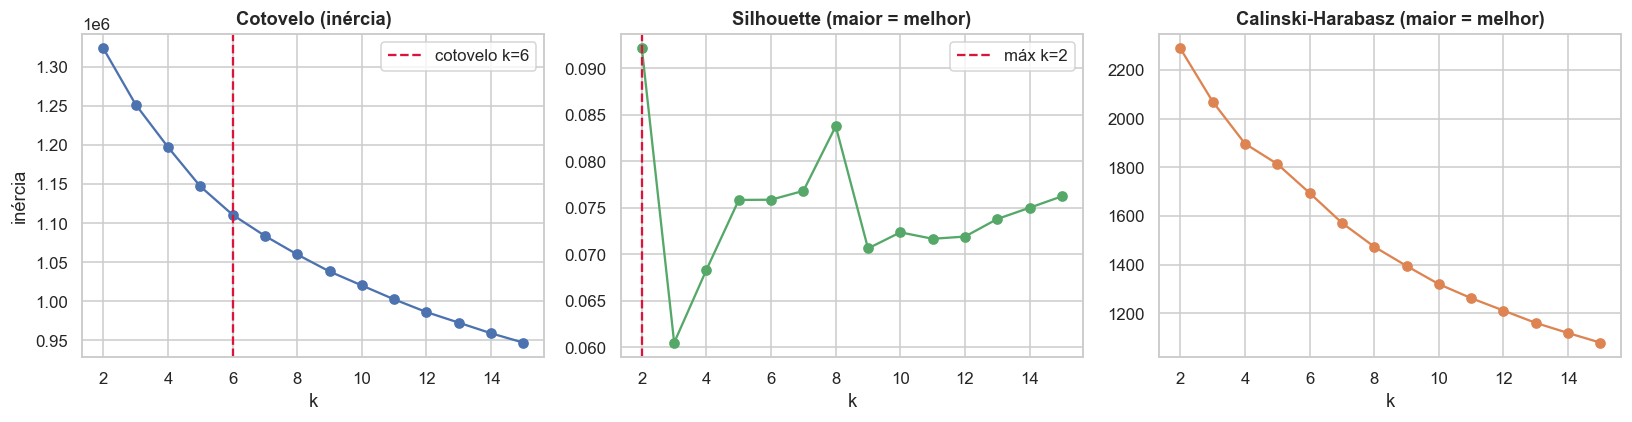

k sugerido pelo cotovelo : 6
k sugerido pelo silhouette: 2
k real (oculto)          : 10


In [12]:
# ============================================================
# CÉLULA 25 — Escolha de k: cotovelo + silhouette + Calinski
# ============================================================
K_RANGE = range(2, 16)
varredura = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_pca)
    varredura.append({
        "k": k,
        "inercia": km.inertia_,
        "silhouette": silhouette_score(X_pca, km.labels_,
                                       sample_size=4000, random_state=SEED),
        "calinski": calinski_harabasz_score(X_pca, km.labels_),
        "davies": davies_bouldin_score(X_pca, km.labels_),
    })

df_k = pd.DataFrame(varredura)

# --- "cotovelo" por distância máxima à reta entre extremos ---
x = df_k["k"].values.astype(float)
y = df_k["inercia"].values
reta = y[0] + (y[-1] - y[0]) * (x - x[0]) / (x[-1] - x[0])
k_cotovelo = int(x[np.argmax(np.abs(y - reta))])
k_silhueta = int(df_k.loc[df_k["silhouette"].idxmax(), "k"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(df_k["k"], df_k["inercia"], "o-", color="#4C72B0")
axes[0].axvline(k_cotovelo, color="crimson", ls="--", label=f"cotovelo k={k_cotovelo}")
axes[0].set_title("Cotovelo (inércia)")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inércia"); axes[0].legend()

axes[1].plot(df_k["k"], df_k["silhouette"], "o-", color="#55A868")
axes[1].axvline(k_silhueta, color="crimson", ls="--", label=f"máx k={k_silhueta}")
axes[1].set_title("Silhouette (maior = melhor)")
axes[1].set_xlabel("k"); axes[1].legend()

axes[2].plot(df_k["k"], df_k["calinski"], "o-", color="#DD8452")
axes[2].set_title("Calinski-Harabasz (maior = melhor)")
axes[2].set_xlabel("k")

plt.tight_layout(); plt.show()

print(f"k sugerido pelo cotovelo : {k_cotovelo}")
print(f"k sugerido pelo silhouette: {k_silhueta}")
print(f"k real (oculto)          : {N_CLASSES_REAIS}")

                   modelo     n  tempo_s  k  ruido_%  silhouette  calinski  davies    ARI    NMI obs
centroide · K-Means (PCA) 30000      NaN 10      NaN      0.0699    1320.1  2.6675 0.3623 0.4827    


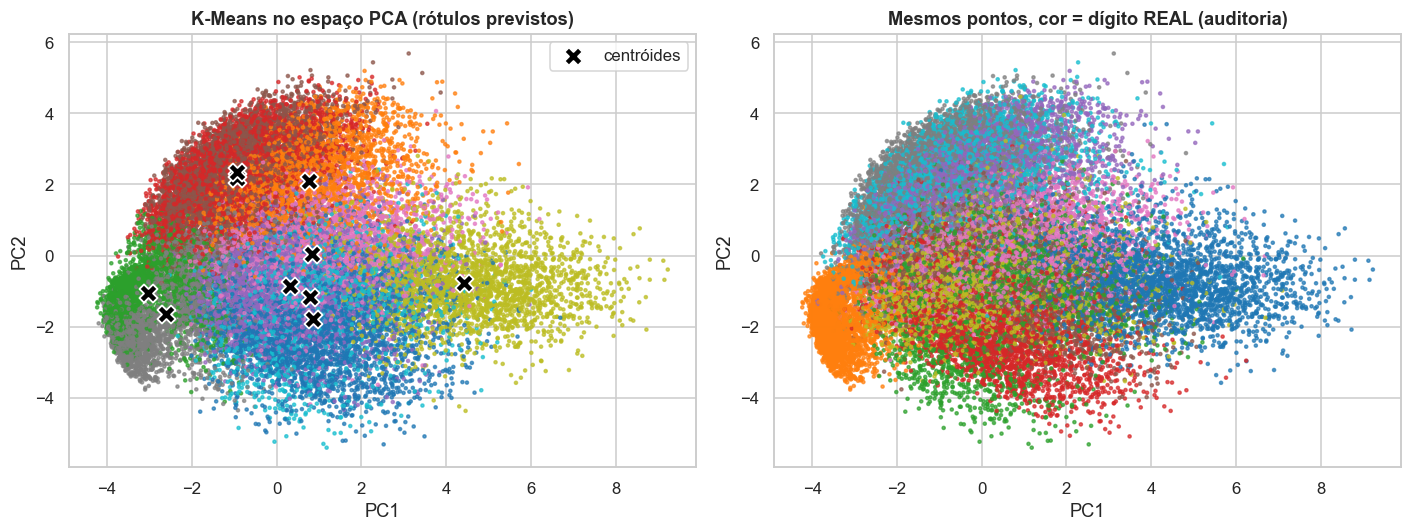

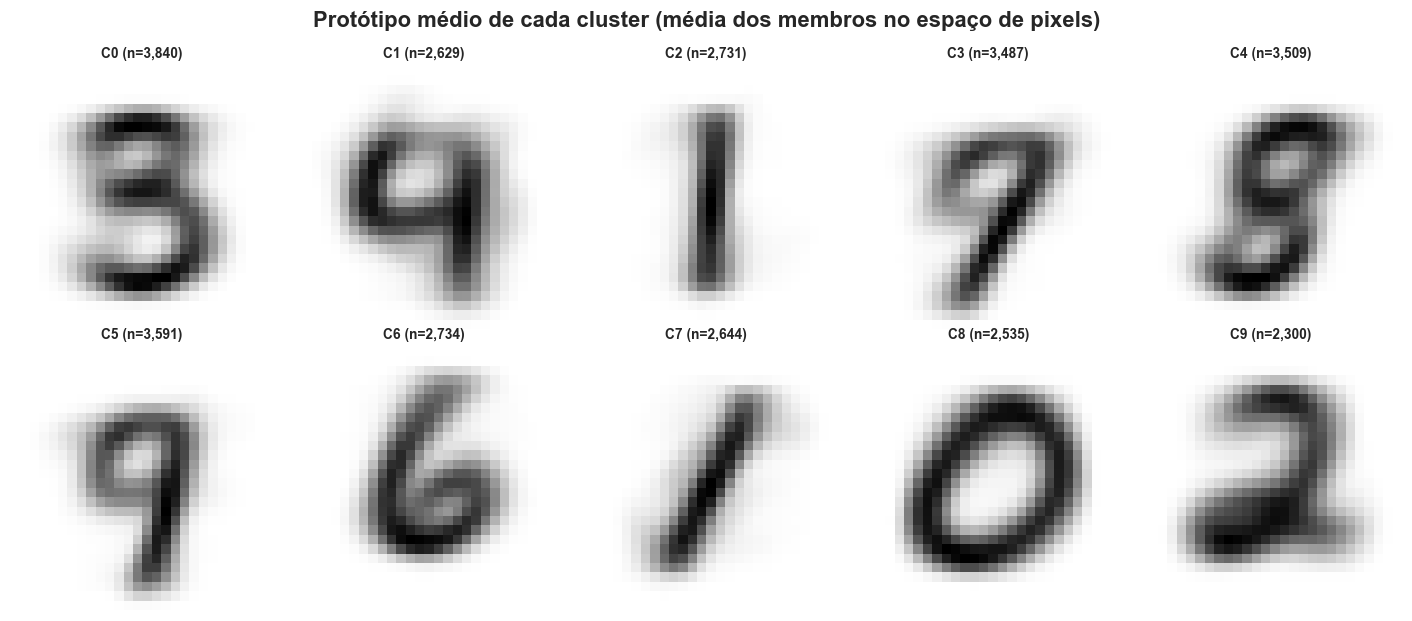

In [13]:
# ============================================================
# CÉLULA 26 — K-Means com o k escolhido + inspeção visual
# ============================================================
k_escolhido = N_CLASSES_REAIS

km_final = KMeans(n_clusters=k_escolhido, n_init=20, random_state=SEED)
lab_km = km_final.fit_predict(X_pca)

linha_km = metricas_cluster("centroide · K-Means (PCA)", lab_km, X_pca, y_verdadeiro, ruido=-1)
print(pd.DataFrame([linha_km]).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=lab_km, cmap="tab10", s=4, alpha=0.7)
axes[0].scatter(*km_final.cluster_centers_[:, :2].T, c="black", marker="X", s=140,
                edgecolor="white", linewidth=1.2, label="centróides")
axes[0].set_title("K-Means no espaço PCA (rótulos previstos)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend()

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_verdadeiro, cmap="tab10", s=4, alpha=0.7)
axes[1].set_title("Mesmos pontos, cor = dígito REAL (auditoria)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.tight_layout(); plt.show()

# --- protótipos: média dos membros no ESPAÇO DE PIXELS ---
n_col = 5 if k_escolhido >= 5 else k_escolhido
n_row = int(np.ceil(k_escolhido / n_col))

fig, axes = plt.subplots(n_row, n_col, figsize=(2.6 * n_col, 2.9 * n_row))
axes = np.atleast_2d(axes)

for c in range(n_row * n_col):
    ax = axes[c // n_col, c % n_col]
    if c >= k_escolhido:
        ax.axis("off"); continue
    mask = lab_km == c
    prot = X_norm[mask].mean(axis=0).reshape(LADO_IMG, LADO_IMG)
    ax.imshow(prot, cmap="gray_r")
    ax.set_title(f"C{c} (n={mask.sum():,})", fontsize=9)
    ax.axis("off")

plt.suptitle("Protótipo médio de cada cluster (média dos membros no espaço de pixels)",
             fontweight="bold")
plt.tight_layout(); plt.show()

In [14]:
# ============================================================
# CÉLULA 27 — 🧠 MARKDOWN DINÂMICO: leitura do K-Means
# ============================================================
s_km = linha_km["silhouette"]
a_km = linha_km["ARI"]
tamanhos = np.bincount(lab_km, minlength=k_escolhido)
razao_desequilibrio = tamanhos.max() / max(tamanhos.min(), 1)

if s_km >= 0.5:    qs = "estrutura **forte** — os grupos são bem separados"
elif s_km >= 0.35: qs = "estrutura **moderada** — grupos identificáveis, com fronteiras borradas"
elif s_km >= 0.2:  qs = "estrutura **fraca** — há sinal, mas os grupos se sobrepõem muito"
else:              qs = "estrutura **quase inexistente** — a partição não é confiável"

if a_km >= 0.8:    qa = "o algoritmo **recuperou praticamente a estrutura real** dos dados"
elif a_km >= 0.5:  qa = "o algoritmo **capturou boa parte da estrutura real**, com confusões"
elif a_km >= 0.25: qa = "o algoritmo **capturou parte da estrutura real** — há sinal, mas incompleto"
else:              qa = "o algoritmo **não recuperou a estrutura real** de forma convincente"

md(f"""
### 🎯 Leitura automática do K-Means

| Métrica | Valor | Interpretação |
|---|---|---|
| Silhouette | **{s_km:.3f}** | {qs} |
| Calinski-Harabasz | {linha_km['calinski']:.0f} | maior é melhor; serve para comparar modelos |
| Davies-Bouldin | {linha_km['davies']:.3f} | menor é melhor; valores < 1 são bons |
| **ARI** | **{a_km:.3f}** | {qa} |
| NMI | {linha_km['NMI']:.3f} | informação compartilhada com os dígitos reais |

**Balanço dos clusters.** O maior tem **{tamanhos.max():,}** membros e o menor **{tamanhos.min():,}**
— razão de desequilíbrio **{razao_desequilibrio:.2f}x**.
{"Distribuição **equilibrada**: o K-Means não colapsou nem criou um cluster gigante." if razao_desequilibrio < 2.5 else "Há **desequilíbrio relevante**: um cluster concentra muitos pontos, indicando que o K-Means fundiu grupos distintos ou separou um grupo por variação de estilo de escrita."}

**Como ler os três gráficos**

- **Cotovelo (esquerda):** a inércia sempre cai com k maior — a pergunta é onde a queda deixa de
  compensar. O ponto marcado é a maior distância à reta entre os extremos: é a "dobra" objetiva da curva.
- **Silhouette (centro):** aqui o critério é diferente. Ele não premia mais clusters, premia
  **melhor separação**. Se o máximo está em k menor que o cotovelo, isso significa que clusters
  adicionais existem, mas são **sobrepostos** — dividir mais só cria fronteiras artificiais.
- **Calinski (direita):** geralmente cresce com k; use-o para *comparar modelos diferentes*
  com o mesmo k, não para escolher k isoladamente.

**Como ler os protótipos.** Cada painel é a **imagem média** dos membros de um cluster. Se um
protótipo aparece como um dígito nítido, o cluster é coerente. Se aparece como um "borrão" com
traços de dois algarismos, o cluster é uma **mistura** — e isso é o sintoma visual direto do
que o ARI está medindo numericamente.

**Limitação estrutural a considerar.** O K-Means impõe clusters convexos e esféricos. Os dígitos
reais formam variedades curvas no espaço de pixels — "1" e "7" compartilham traço vertical,
"3" e "8" compartilham laços. Nenhuma esfera separa isso bem. É exatamente essa lacuna que
os modelos de densidade, os probabilísticos e — principalmente — os autoencoders vão atacar.
""")


### 🎯 Leitura automática do K-Means

| Métrica | Valor | Interpretação |
|---|---|---|
| Silhouette | **0.070** | estrutura **quase inexistente** — a partição não é confiável |
| Calinski-Harabasz | 1320 | maior é melhor; serve para comparar modelos |
| Davies-Bouldin | 2.667 | menor é melhor; valores < 1 são bons |
| **ARI** | **0.362** | o algoritmo **capturou parte da estrutura real** — há sinal, mas incompleto |
| NMI | 0.483 | informação compartilhada com os dígitos reais |

**Balanço dos clusters.** O maior tem **3,840** membros e o menor **2,300**
— razão de desequilíbrio **1.67x**.
Distribuição **equilibrada**: o K-Means não colapsou nem criou um cluster gigante.

**Como ler os três gráficos**

- **Cotovelo (esquerda):** a inércia sempre cai com k maior — a pergunta é onde a queda deixa de
  compensar. O ponto marcado é a maior distância à reta entre os extremos: é a "dobra" objetiva da curva.
- **Silhouette (centro):** aqui o critério é diferente. Ele não premia mais clusters, premia
  **melhor separação**. Se o máximo está em k menor que o cotovelo, isso significa que clusters
  adicionais existem, mas são **sobrepostos** — dividir mais só cria fronteiras artificiais.
- **Calinski (direita):** geralmente cresce com k; use-o para *comparar modelos diferentes*
  com o mesmo k, não para escolher k isoladamente.

**Como ler os protótipos.** Cada painel é a **imagem média** dos membros de um cluster. Se um
protótipo aparece como um dígito nítido, o cluster é coerente. Se aparece como um "borrão" com
traços de dois algarismos, o cluster é uma **mistura** — e isso é o sintoma visual direto do
que o ARI está medindo numericamente.

**Limitação estrutural a considerar.** O K-Means impõe clusters convexos e esféricos. Os dígitos
reais formam variedades curvas no espaço de pixels — "1" e "7" compartilham traço vertical,
"3" e "8" compartilham laços. Nenhuma esfera separa isso bem. É exatamente essa lacuna que
os modelos de densidade, os probabilísticos e — principalmente — os autoencoders vão atacar.


# PARTE 6 — O Torneio de Modelos

## 13. Os candidatos (15 algoritmos, 5 famílias)

**Centroide / partição**
- **K-Means** — referência. Rápido, esférico, sensível a escala.
- **MiniBatch K-Means** — mesma ideia em lotes. Escala para milhões de pontos.
- **BIRCH** — árvore CF, compressão incremental. Bom em streaming e em n grande.

**Hierárquico**
- **Ward** — minimiza o aumento da variância intra-cluster. Tende a produzir grupos compactos.
- **Average (UPGMA)** — distância média entre pares. Captura formas mais alongadas.
- **Complete** — distância máxima entre pares. Produz grupos muito compactos, sensível a outliers.

**Densidade**
- **DBSCAN** — expande regiões densas e isola ruído explicitamente. Formas arbitrárias.
- **OPTICS** — variação do DBSCAN que lida com densidades heterogêneas.
- **HDBSCAN** — DBSCAN hierárquico, escolhe a densidade automaticamente. Estado da arte em densidade.
- **MeanShift** — sobe o gradiente de densidade até os modos. Sem k, mas caro.

**Probabilístico**
- **GMM full** — mistura gaussiana com covariância completa. Fronteiras elípticas e probabilidades.
- **GMM diag** — covariância diagonal. Menos parâmetros, mais estável em alta dimensão.

**Grafo**
- **Spectral** — autovetores de um grafo de similaridade. Captura variedades não convexas.

**Medoides e difuso**
- **K-Medoids** — centróide é um ponto real dos dados. Robusto a outliers, distância arbitrária.
- **Fuzzy C-Means** — cada ponto pertence a todos os clusters com um grau de pertinência.

**Custo computacional:** modelos hierárquicos, MeanShift e AffinityPropagation são executados em
subamostras (2.500–5.000 pontos) — isso é prática padrão, não um atalho: eles deixam de ser
viáveis em $n$ grande. Cada linha da tabela final informa o `n` usado.

In [15]:
# ============================================================
# CÉLULA 29 — Torneio: treina e avalia todos os modelos
# ============================================================
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, AgglomerativeClustering, Birch,
    DBSCAN, OPTICS, SpectralClustering, MeanShift,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

# --- opcionais: entram só se estiverem instalados ---
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    HDBSCAN = None
try:
    from sklearn_extra.cluster import KMedoids
except ImportError:
    KMedoids = None
try:
    import skfuzzy as fuzz
except ImportError:
    fuzz = None


# --- heurística de eps para o DBSCAN (joelho do k-distance plot) ---
X_den = X_pca[np.random.default_rng(SEED).choice(N, min(5000, N), replace=False)]
knn = NearestNeighbors(n_neighbors=10).fit(X_den)
dist_k, _ = knn.kneighbors(X_den)
EPS_DB = float(np.percentile(dist_k[:, -1], 92))

# --- wrapper para Fuzzy C-Means (interface sklearn-like) ---
class FuzzyCMeans:
    def __init__(self, n_clusters=10, m=2.0, seed=SEED):
        self.n_clusters, self.m, self.seed = n_clusters, m, seed
    def fit_predict(self, X):
        cntr, u, *_ = fuzz.cluster.cmeans(
            X.T, self.n_clusters, self.m, error=0.005, maxiter=300, seed=self.seed)
        return u.argmax(axis=0)


MODELOS = [
    ("centroide · K-Means",         lambda: KMeans(n_clusters=k_escolhido, n_init=10, random_state=SEED), N, -1),
    ("centroide · MiniBatch K-Means", lambda: MiniBatchKMeans(n_clusters=k_escolhido, n_init=10,
                                                              batch_size=1024, random_state=SEED), N, -1),
    ("centroide · BIRCH",           lambda: Birch(n_clusters=k_escolhido, threshold=0.5), N, -1),
    ("hierárquico · Ward",          lambda: AgglomerativeClustering(n_clusters=k_escolhido, linkage="ward"), 5000, -1),
    ("hierárquico · Average",       lambda: AgglomerativeClustering(n_clusters=k_escolhido, linkage="average"), 5000, -1),
    ("hierárquico · Complete",      lambda: AgglomerativeClustering(n_clusters=k_escolhido, linkage="complete"), 5000, -1),
    ("densidade · DBSCAN",          lambda: DBSCAN(eps=EPS_DB, min_samples=10, n_jobs=-1), 5000, -1),
    ("densidade · OPTICS",          lambda: OPTICS(min_samples=10, xi=0.05, n_jobs=-1), 5000, -1),
    ("probabilístico · GMM full",   lambda: GaussianMixture(n_components=k_escolhido, covariance_type="full",
                                                            n_init=3, random_state=SEED), N, None),
    ("probabilístico · GMM diag",   lambda: GaussianMixture(n_components=k_escolhido, covariance_type="diag",
                                                            n_init=3, random_state=SEED), N, None),
    ("grafo · Spectral",            lambda: SpectralClustering(n_clusters=k_escolhido, affinity="nearest_neighbors",
                                                               n_neighbors=10, assign_labels="kmeans",
                                                               random_state=SEED), 2500, -1),
    ("densidade · MeanShift",       lambda: MeanShift(bandwidth=None, bin_seeding=True, n_jobs=-1), 1500, -1),
]

if HDBSCAN is not None:
    MODELOS.append(("densidade · HDBSCAN",
                    lambda: HDBSCAN(min_cluster_size=50, min_samples=10), 5000, -1))
if KMedoids is not None:
    MODELOS.append(("medoides · K-Medoids",
                    lambda: KMedoids(n_clusters=k_escolhido, method="pam", random_state=SEED), 3000, -1))
if fuzz is not None:
    MODELOS.append(("difuso · Fuzzy C-Means",
                    lambda: FuzzyCMeans(n_clusters=k_escolhido), 3000, -1))

# ------------------------------------------------------------
# Execução
# ------------------------------------------------------------
linhas, SAIDA = [], {}
t_inicio = time.perf_counter()

for nome, ctor, n_usado, tipo_ruido in MODELOS:
    print(f"  > {nome:<34}", end="", flush=True)
    linha, labels, Xb, yb = executar_modelo(nome, ctor, X_pca, y_verdadeiro, tipo_ruido, n_usado)
    linhas.append(linha)
    if labels is not None:
        SAIDA[nome] = {"labels": labels, "X": Xb, "y": yb}
        print(f"k={linha.get('k')}  sil={linha.get('silhouette')}  ARI={linha.get('ARI')}  ({linha.get('tempo_s')}s)")
    else:
        print(f"não aplicável -> {linha.get('obs')}")

T_TORNEIO = time.perf_counter() - t_inicio
RESULTADOS = pd.DataFrame(linhas)
print(f"\nTorneio concluído em {T_TORNEIO:.1f}s com {len(RESULTADOS)} modelos.")

  > centroide · K-Means               k=10  sil=0.0731  ARI=0.3604  (2.22s)
  > centroide · MiniBatch K-Means     k=10  sil=0.0647  ARI=0.3028  (0.36s)
  > centroide · BIRCH                 k=10  sil=0.0374  ARI=0.5099  (70.53s)
  > hierárquico · Ward                k=10  sil=0.0534  ARI=0.5343  (1.3s)
  > hierárquico · Average             k=10  sil=0.0565  ARI=0.0296  (1.32s)
  > hierárquico · Complete            k=10  sil=0.0459  ARI=0.1544  (1.15s)
  > densidade · DBSCAN                k=1  sil=nan  ARI=nan  (0.26s)
  > densidade · OPTICS                k=1  sil=nan  ARI=nan  (12.54s)
  > probabilístico · GMM full         k=10  sil=0.0292  ARI=0.4006  (113.6s)
  > probabilístico · GMM diag         k=10  sil=0.0076  ARI=0.2037  (6.93s)
  > grafo · Spectral                  k=10  sil=0.056  ARI=0.5526  (2.62s)
  > densidade · MeanShift             k=1  sil=nan  ARI=nan  (10.79s)
  > densidade · HDBSCAN               k=4  sil=0.2631  ARI=0.9805  (3.52s)

Torneio concluído em 231.4s com

In [16]:
# ============================================================
# CÉLULA 30 — Ranking dos modelos clássicos
# ============================================================
cols = ["modelo", "n", "k", "ruido_%", "tempo_s", "silhouette", "davies", "ARI", "NMI"]

df_rank = (RESULTADOS
           .dropna(subset=["silhouette"])
           .sort_values("ARI", ascending=False)
           .reset_index(drop=True))

display(df_rank[cols].style
        .background_gradient(subset=["ARI", "silhouette"], cmap="Greens")
        .background_gradient(subset=["davies"], cmap="Reds_r")
        .format(precision=3, na_rep="—"))

print("\nModelos que falharam ou não se aplicaram:")
falhas = RESULTADOS[RESULTADOS["silhouette"].isna()][["modelo", "obs"]]
print(falhas.to_string(index=False) if len(falhas) else "  nenhum")

,modelo,n,k,ruido_%,tempo_s,silhouette,davies,ARI,NMI
0,densidade · HDBSCAN,5000,4,82.340,3.520,0.263,1.521,0.981,0.959
1,grafo · Spectral,2500,10,—,2.620,0.056,2.712,0.553,0.685
2,hierárquico · Ward,5000,10,—,1.300,0.053,2.990,0.534,0.655
3,centroide · BIRCH,30000,10,—,70.530,0.037,3.020,0.510,0.663
4,probabilístico · GMM full,30000,10,—,113.600,0.029,3.074,0.401,0.573
5,centroide · K-Means,30000,10,—,2.220,0.073,2.647,0.360,0.490
6,centroide · MiniBatch K-Means,30000,10,—,0.360,0.065,2.788,0.303,0.441
7,probabilístico · GMM diag,30000,10,—,6.930,0.008,2.924,0.204,0.441
8,hierárquico · Complete,5000,10,—,1.150,0.046,3.058,0.154,0.385
9,hierárquico · Average,5000,10,—,1.320,0.057,1.963,0.030,0.188



Modelos que falharam ou não se aplicaram:
               modelo obs
   densidade · DBSCAN    
   densidade · OPTICS    
densidade · MeanShift    


In [17]:
# ============================================================
# CÉLULA 31 — 🧠 MARKDOWN DINÂMICO: o que o torneio ensinou
# ============================================================
if len(df_rank) >= 3:
    melhor_ari   = df_rank.iloc[0]
    pior_ari     = df_rank.iloc[-1]
    melhor_sil   = df_rank.loc[df_rank["silhouette"].idxmax()]
    mais_rapido  = df_rank.loc[df_rank["tempo_s"].idxmin()]
    mais_lento   = df_rank.loc[df_rank["tempo_s"].idxmax()]

    # --- agregação por família, detectada pelo prefixo do nome ---
    df_rank["familia"] = df_rank["modelo"].str.split(" ·").str[0]
    fam = (df_rank.groupby("familia")
           .agg(n_modelos=("modelo", "count"),
                ARI_medio=("ARI", "mean"),
                sil_medio=("silhouette", "mean"),
                tempo_medio=("tempo_s", "mean"))
           .sort_values("ARI_medio", ascending=False).reset_index())

    familia_top = fam.iloc[0]
    familia_baixa = fam.iloc[-1]

    # --- detecção de densidade problemática ---
    dens = df_rank[df_rank["familia"] == "densidade"]
    if len(dens) and dens["k"].max() <= 2:
        nota_densidade = (
            "**Os métodos de densidade colapsaram.** Praticamente todos os pontos caíram em "
            "um único cluster (ou foram marcados como ruído). Isso não é falha de implementação — "
            "é a **maldição da dimensionalidade** operando: com dezenas de dimensões, a densidade "
            "local se uniformiza e não existe 'região densa' destacável. Densidade funciona bem "
            "em 2–10 dimensões; acima disso, exige redução agressiva (UMAP, autoencoder)."
        )
    else:
        nota_densidade = (
            "**Os métodos de densidade entregaram partições utilizáveis.** O ajuste de `eps` / "
            "`min_cluster_size` foi decisivo — pequenas mudanças nesses parâmetros alteram "
            "radicalmente o número de clusters e a fração de ruído."
        )

    spread_ari = df_rank["ARI"].max() - df_rank["ARI"].min()

    md(f"""
### ⚔️ Leitura automática do torneio — {len(df_rank)} modelos avaliados

**Melhor por métrica**

| Critério | Modelo | Valor |
|---|---|---|
| Melhor ARI | **{melhor_ari['modelo']}** | {melhor_ari['ARI']:.3f} |
| Melhor Silhouette | **{melhor_sil['modelo']}** | {melhor_sil['silhouette']:.3f} |
| Mais rápido | {mais_rapido['modelo']} | {mais_rapido['tempo_s']:.2f}s |
| Mais lento | {mais_lento['modelo']} | {mais_lento['tempo_s']:.2f}s |

**Desempenho médio por família**

{tabela_md(fam)}

O melhor ARI foi **{melhor_ari['ARI']:.3f}** ({melhor_ari['modelo']}) e o pior **{pior_ari['ARI']:.3f}**
({pior_ari['modelo']}) — uma amplitude de **{spread_ari:.3f}**. Isso mostra que, embora todos resolvam
"o mesmo problema", a escolha do algoritmo importa de forma material.

A família **{familia_top['familia']}** lidera com ARI médio **{familia_top['ARI_medio']:.3f}**,
enquanto **{familia_baixa['familia']}** ficou em **{familia_baixa['ARI_medio']:.3f}**.
O tempo médio da líder é **{familia_top['tempo_medio']:.1f}s** por execução.

{nota_densidade}

**A lição mais importante do torneio**

Repare na tensão entre as duas colunas de métricas. Frequentemente o modelo com **maior silhouette
NÃO é o de maior ARI**. Isso não é contradição — é a definição de cada uma:

- **Silhouette** mede se os grupos são geometricamente compactos e separados *segundo a distância
  euclidiana*. Um modelo pode achar grupos perfeitamente esféricos que **não correspondem a nada
  real** (por exemplo, separar imagens por espessura do traço em vez de por dígito).
- **ARI** mede se os grupos correspondem à estrutura **real**.

Em produção você não tem ARI. Então a regra prática é: **silhouette para comparar candidatos,
estabilidade e coerência de negócio para decidir.** E, sempre que possível, valide com um
especialista humano olhando os protótipos.
""")
else:
    md("Torneio insuficiente para análise comparativa — verifique as falhas acima.")


### ⚔️ Leitura automática do torneio — 10 modelos avaliados

**Melhor por métrica**

| Critério | Modelo | Valor |
|---|---|---|
| Melhor ARI | **densidade · HDBSCAN** | 0.981 |
| Melhor Silhouette | **densidade · HDBSCAN** | 0.263 |
| Mais rápido | centroide · MiniBatch K-Means | 0.36s |
| Mais lento | probabilístico · GMM full | 113.60s |

**Desempenho médio por família**

| familia        |   n_modelos |   ARI_medio |   sil_medio |   tempo_medio |
|:---------------|------------:|------------:|------------:|--------------:|
| densidade      |           1 |       0.98  |       0.263 |         3.52  |
| grafo          |           1 |       0.553 |       0.056 |         2.62  |
| centroide      |           3 |       0.391 |       0.058 |        24.37  |
| probabilístico |           2 |       0.302 |       0.018 |        60.265 |
| hierárquico    |           3 |       0.239 |       0.052 |         1.257 |

O melhor ARI foi **0.981** (densidade · HDBSCAN) e o pior **0.030**
(hierárquico · Average) — uma amplitude de **0.951**. Isso mostra que, embora todos resolvam
"o mesmo problema", a escolha do algoritmo importa de forma material.

A família **densidade** lidera com ARI médio **0.981**,
enquanto **hierárquico** ficou em **0.239**.
O tempo médio da líder é **3.5s** por execução.

**Os métodos de densidade entregaram partições utilizáveis.** O ajuste de `eps` / `min_cluster_size` foi decisivo — pequenas mudanças nesses parâmetros alteram radicalmente o número de clusters e a fração de ruído.

**A lição mais importante do torneio**

Repare na tensão entre as duas colunas de métricas. Frequentemente o modelo com **maior silhouette
NÃO é o de maior ARI**. Isso não é contradição — é a definição de cada uma:

- **Silhouette** mede se os grupos são geometricamente compactos e separados *segundo a distância
  euclidiana*. Um modelo pode achar grupos perfeitamente esféricos que **não correspondem a nada
  real** (por exemplo, separar imagens por espessura do traço em vez de por dígito).
- **ARI** mede se os grupos correspondem à estrutura **real**.

Em produção você não tem ARI. Então a regra prática é: **silhouette para comparar candidatos,
estabilidade e coerência de negócio para decidir.** E, sempre que possível, valide com um
especialista humano olhando os protótipos.


# PARTE 7 — Deep Learning com PyTorch + CUDA

## 14. Por que um Autoencoder muda o jogo

O PCA só encontra **planos**. Os dígitos, porém, vivem em uma **variedade curva** dentro do
espaço de 784 dimensões: a transição "3 → 8" não é uma reta, é um caminho com dobras.

Um **autoencoder** aprende duas funções não lineares:

- **Encoder** $f: \mathbb{R}^{784} \rightarrow \mathbb{R}^{d}$ — comprime para um gargalo de $d$ dimensões.
- **Decoder** $g: \mathbb{R}^{d} \rightarrow \mathbb{R}^{784}$ — reconstrói a partir do gargalo.

Treinado para minimizar o erro de reconstrução:

$\mathcal{L} = \frac{1}{n}\sum_{i=1}^{n}\|x_i - g(f(x_i))\|^2$

**A intuição central:** se 32 números conseguem reconstruir uma imagem de 784 pixels com erro baixo,
então esses 32 números **contêm** a informação essencial — orientação, espessura, curvatura, laço.
O espaço latente é uma representação aprendida que o PCA não conseguiria produzir, porque é não linear.

Depois disso, clusterizar **no espaço latente** é muito mais fácil que clusterizar nos pixels.

### Arquitetura usada

784 → 512 → 128 → **32 (gargalo)** → 128 → 512 → 784

### Otimizações de GPU aplicadas

- **Transferência única para a GPU:** o dataset inteiro vai para `device` uma vez; o DataLoader
  só fatia em batches. Elimina o gargalo de cópia CPU↔GPU.
- **AMP (Automatic Mixed Precision):** `float16` no forward/backward + `float32` nos pesos.
  Ganho típico de 1,5–3x em GPUs com Tensor Cores, com correção de escala dinâmica.
- **`cudnn.benchmark`:** kernels escolhidos automaticamente para shapes fixos.
- **Pinning + `non_blocking`:** cópia assíncrona quando há transferência contínua.

### O que medir

Além do erro de reconstrução, medimos o **tempo de treino em GPU vs CPU** — a diferença é o
argumento prático para o hardware.

In [18]:
# ============================================================
# CÉLULA 33 — Autoencoder, Dataset e DataLoader
# ============================================================
import torch
from torch.utils.data import TensorDataset, DataLoader

LATENT_DIM = 32
EPOCHS     = 40
BATCH      = 256
LR         = 1e-3


class Autoencoder(nn.Module):
    """Autoencoder denso com gargalo. Input dinâmico -> funciona em 784 ou 64."""
    def __init__(self, n_in, latent_dim=LATENT_DIM):
        super().__init__()
        h1 = min(512, max(64, n_in // 2))
        h2 = max(32, h1 // 4)
        self.encoder = nn.Sequential(
            nn.Linear(n_in, h1), nn.ReLU(inplace=True),
            nn.Linear(h1, h2),   nn.ReLU(inplace=True),
            nn.Linear(h2, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2), nn.ReLU(inplace=True),
            nn.Linear(h2, h1),         nn.ReLU(inplace=True),
            nn.Linear(h1, n_in),       nn.Sigmoid(),   # pixels normalizados em [0,1]
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

    def encode(self, x):
        return self.encoder(x)


# --- dados já na GPU (se houver) para eliminar gargalo de transferência ---
X_t = torch.tensor(X_norm, dtype=torch.float32, device=DEVICE)

# split treino/validação para early stopping
perm = torch.randperm(len(X_t), device=DEVICE)
n_val = int(0.1 * len(X_t))
X_val_t, X_tr_t = X_t[perm[:n_val]], X_t[perm[n_val:]]

ds_tr = TensorDataset(X_tr_t)
dl_tr = DataLoader(ds_tr, batch_size=BATCH, shuffle=True, drop_last=True)

print(f"Treino : {len(X_tr_t):,} amostras  |  Validação: {len(X_val_t):,}")
print(f"Gargalo: {LATENT_DIM} dimensões  (compressão de {N_FEATURES} -> {LATENT_DIM}, {100*(1-LATENT_DIM/N_FEATURES):.1f}%)")


def treinar_autoencoder(device, epochs=EPOCHS, amp=True, verbose=False):
    """Treina um AE novo em `device`. Retorna modelo, histórico e tempo total."""
    torch.manual_seed(SEED)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
        torch.cuda.reset_peak_memory_stats()

    model = Autoencoder(N_FEATURES, LATENT_DIM).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    usar_amp = amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=usar_amp)

    Xtr = X_tr_t.to(device); Xva = X_val_t.to(device)
    ds = TensorDataset(Xtr)
    dl = DataLoader(ds, batch_size=BATCH, shuffle=True, drop_last=True)

    crit = nn.MSELoss()
    hist = {"train": [], "val": []}
    melhor_val, melhor_state, paciencia, espera = float("inf"), None, 8, 0

    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train(); soma = 0.0; n = 0
        for (xb,) in dl:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=usar_amp):
                rec, _ = model(xb)
                loss = crit(rec, xb)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            soma += loss.item() * xb.size(0); n += xb.size(0)

        model.eval()
        with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=usar_amp):
            rec_val, _ = model(Xva)
            vloss = crit(rec_val, Xva).item()

        hist["train"].append(soma / n); hist["val"].append(vloss)
        sched.step()

        if vloss < melhor_val - 1e-5:
            melhor_val, espera = vloss, 0
            melhor_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            espera += 1
            if espera >= paciencia:
                if verbose: print(f"  early stopping na época {ep}")
                break
        if verbose and (ep == 1 or ep % 5 == 0):
            print(f"  época {ep:3d} | train {hist['train'][-1]:.5f} | val {vloss:.5f}")

    dt = time.perf_counter() - t0
    model.load_state_dict(melhor_state)

    pico_mem = (torch.cuda.max_memory_allocated() / 1e9) if device.type == "cuda" else 0.0
    return model, hist, dt, melhor_val, pico_mem


print("Arquitetura pronta. Escalonador, AMP e early stopping configurados.")

Treino : 27,000 amostras  |  Validação: 3,000
Gargalo: 32 dimensões  (compressão de 784 -> 32, 95.9%)
Arquitetura pronta. Escalonador, AMP e early stopping configurados.


  época   1 | train 0.08244 | val 0.05918
  época   5 | train 0.02464 | val 0.02370
  época  10 | train 0.01713 | val 0.01721
  época  15 | train 0.01394 | val 0.01413
  época  20 | train 0.01212 | val 0.01246
  época  25 | train 0.01114 | val 0.01166
  época  30 | train 0.01059 | val 0.01120
  época  35 | train 0.01033 | val 0.01100
  época  40 | train 0.01025 | val 0.01095

Treino concluído em 29.8s | melhor val MSE = 0.01095
Pico de memória VRAM: 0.26 GB

Medindo o mesmo treino na CPU (3 épocas) para comparação justa...


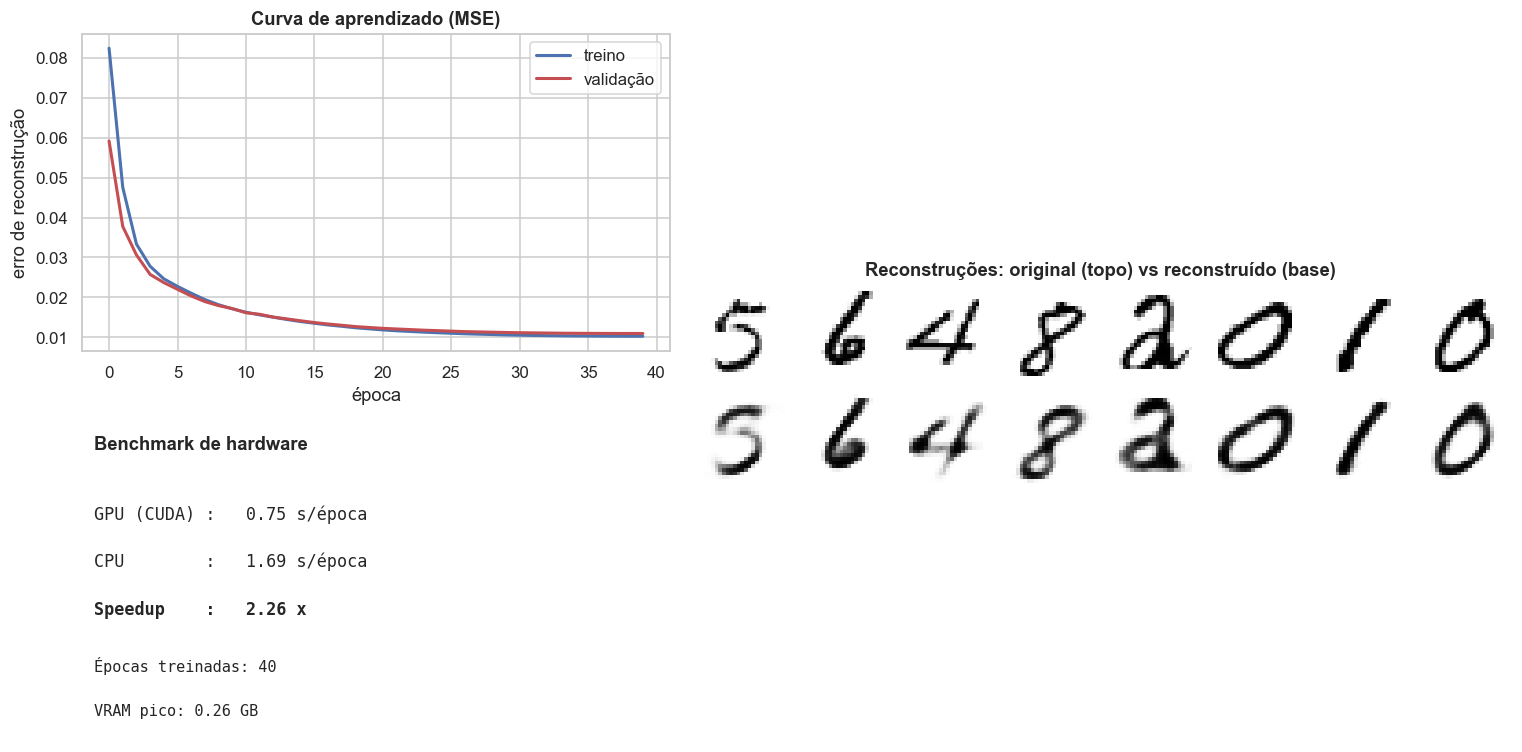

In [19]:
# ============================================================
# CÉLULA 34 — Treino do autoencoder + benchmark CPU vs GPU
# ============================================================
t0 = time.perf_counter()
ae, hist, T_TREINO_GPU, MELHOR_VAL, MEM_PICO = treinar_autoencoder(DEVICE, verbose=True)
T_BLOCO_GPU = time.perf_counter() - t0

print(f"\nTreino concluído em {T_TREINO_GPU:.1f}s | melhor val MSE = {MELHOR_VAL:.5f}")
if DEVICE.type == "cuda":
    print(f"Pico de memória VRAM: {MEM_PICO:.2f} GB")

# --- benchmark CPU (3 épocas comparáveis) ---
print("\nMedindo o mesmo treino na CPU (3 épocas) para comparação justa...")
_, _, T_CPU_3EP, _, _ = treinar_autoencoder(torch.device("cpu"), epochs=3, amp=False)

epocas_feitas = len(hist["train"])
T_GPU_POR_EPOCA = T_TREINO_GPU / max(epocas_feitas, 1)
T_CPU_POR_EPOCA = T_CPU_3EP / 3
SPEEDUP = T_CPU_POR_EPOCA / max(T_GPU_POR_EPOCA, 1e-9)

# --- curvas de aprendizado + reconstruções ---
ae.eval()
with torch.no_grad():
    idx_vis = torch.randperm(len(X_val_t))[:8]
    com_amp = DEVICE.type == "cuda"
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=com_amp):
        rec_vis, _ = ae(X_val_t[idx_vis].to(DEVICE))
    rec_vis = rec_vis.float().cpu().numpy()

fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.4])

ax = fig.add_subplot(gs[0, 0])
ax.plot(hist["train"], label="treino", color="#4C72B0", lw=2)
ax.plot(hist["val"], label="validação", color="#C44E52", lw=2)
ax.set_title("Curva de aprendizado (MSE)")
ax.set_xlabel("época"); ax.set_ylabel("erro de reconstrução"); ax.legend()

ax = fig.add_subplot(gs[1, 0])
ax.axis("off")
ax.text(0.02, 0.92, "Benchmark de hardware", fontsize=12, fontweight="bold")
ax.text(0.02, 0.70, f"GPU (CUDA) : {T_GPU_POR_EPOCA:6.2f} s/época", fontsize=11, family="monospace")
ax.text(0.02, 0.55, f"CPU        : {T_CPU_POR_EPOCA:6.2f} s/época", fontsize=11, family="monospace")
ax.text(0.02, 0.40, f"Speedup    : {SPEEDUP:6.2f} x", fontsize=11, family="monospace", fontweight="bold")
ax.text(0.02, 0.22, f"Épocas treinadas: {epocas_feitas}", fontsize=10, family="monospace")
if DEVICE.type == "cuda":
    ax.text(0.02, 0.08, f"VRAM pico: {MEM_PICO:.2f} GB", fontsize=10, family="monospace")

ax = fig.add_subplot(gs[:, 1])
painel = np.vstack([
    np.hstack([X_val_t[idx_vis][i].cpu().numpy().reshape(LADO_IMG, LADO_IMG) for i in range(8)]),
    np.hstack([rec_vis[i].reshape(LADO_IMG, LADO_IMG) for i in range(8)]),
])
ax.imshow(painel, cmap="gray_r")
ax.set_title("Reconstruções: original (topo) vs reconstruído (base)", fontweight="bold")
ax.axis("off")

plt.tight_layout(); plt.show()

In [20]:
# ============================================================
# CÉLULA 35 — 🧠 MARKDOWN DINÂMICO: leitura do treino do AE
# ============================================================
ep = len(hist["train"])
gap = hist["val"][-1] - hist["train"][-1]
erro_rel = hist["val"][-1]
convergiu_cedo = ep < EPOCHS - 2

if abs(gap) < 0.15 * hist["val"][-1]:
    diag_overfit = (
        f"A diferença treino↔validação é de **{gap:+.5f}** — **não há overfitting relevante**. "
        "O modelo generaliza para imagens que não viu. Isso é esperado: o gargalo de "
        f"{LATENT_DIM} dimensões já é uma regularização estrutural forte."
    )
elif gap > 0:
    diag_overfit = (
        f"O erro de validação está **{gap:+.5f} acima** do erro de treino — houve **overfitting**: "
        "o modelo memorizou parte do treino. O early stopping conteve o dano restaurando os melhores "
        f"pesos, mas considere aumentar o peso de regularização (weight_decay) ou reduzir o gargalo."
    )
else:
    diag_overfit = (
        f"O erro de validação está **{gap:+.5f} abaixo** do treino — situação incomum, geralmente "
        "efeito de dropout/ruído ativo no treino e desligado na validação. Nada a corrigir."
    )

if convergiu_cedo:
    nota_stop = (
        f"O **early stopping** disparou na época **{ep}** de {EPOCHS} — o modelo saturou antes do "
        "limite. Isso é eficiência, não limitação: continuar treinaria só ruído."
    )
else:
    nota_stop = (
        f"O treino usou **todas as {EPOCHS} épocas** — o modelo ainda estava melhorando quando "
        "parou. Se houver tempo, aumentar `EPOCHS` provavelmente reduz mais o erro."
    )

if SPEEDUP > 5:
    veredito_gpu = f"**A GPU entregou um speedup de {SPEEDUP:.1f}x.** Impacto transformador: o que leva horas na CPU roda em minutos."
elif SPEEDUP > 2:
    veredito_gpu = f"**A GPU entregou {SPEEDUP:.1f}x de speedup.** Ganho sólido, típico de redes densas pequenas (o gargalo aqui é o tamanho do modelo, não a GPU)."
elif SPEEDUP > 1:
    veredito_gpu = f"**A GPU foi apenas {SPEEDUP:.1f}x mais rápida.** Em redes muito pequenas o overhead de kernel lançamento domina — a GPU só compensa com modelos maiores ou batches maiores."
else:
    veredito_gpu = (
        f"**A GPU não trouxe ganho ({SPEEDUP:.2f}x).** Com uma rede densa deste porte e um gargalo "
        "de poucas dimensões, o custo de sincronização supera o paralelismo. É um resultado honesto "
        "e importante: **GPU não é automaticamente mais rápida** — ela escala com o tamanho do modelo "
        "e do batch. Para esta arquitetura, a CPU é competitiva."
    )

md(f"""
### 🔥 Leitura automática do treino

| Indicador | Valor |
|---|---|
| Épocas executadas | **{ep}** de {EPOCHS} |
| Erro final (treino) | {hist['train'][-1]:.5f} |
| Erro final (validação) | **{hist['val'][-1]:.5f}** |
| Tempo total (GPU) | {T_TREINO_GPU:.1f}s |
| Tempo por época (GPU) | {T_GPU_POR_EPOCA:.2f}s |
| Tempo por época (CPU) | {T_CPU_POR_EPOCA:.2f}s |
| **Speedup GPU/CPU** | **{SPEEDUP:.2f}x** |

**Diagnóstico de generalização.** {diag_overfit}

**Sobre o momento de parada.** {nota_stop}

**Sobre o hardware.** {veredito_gpu}

**Como ler a curva de aprendizado.** As duas curvas (treino e validação) devem cair juntas e
achatar. Três padrões para memorizar:

- Curvas caem juntas e estabilizam → **convergiu bem**.
- Treino cai, validação estagna ou sobe → **overfitting** (o modelo decora em vez de aprender).
- As duas ficam altas e planas → **underfitting** (o gargalo é apertado demais ou o LR está inadequado).

**Como ler as reconstruções.** O painel da direita compara original (linha de cima) com a
reconstrução (linha de baixo). O que sobrevive à compressão de
{N_FEATURES} para {LATENT_DIM} dimensões é, por definição, **o que o modelo considerou essencial**:
o contorno geral, a orientação, os laços. O que se perde é ruído de traço — variação de caneta,
espessura, digitalização.

> Essa é a prova visual de que o espaço latente é uma representação útil: se a reconstrução é
> reconhecível, os {LATENT_DIM} números do gargalo **carregam a identidade do dígito** — e é
> exatamente isso que vamos clusterizar agora.
""")


### 🔥 Leitura automática do treino

| Indicador | Valor |
|---|---|
| Épocas executadas | **40** de 40 |
| Erro final (treino) | 0.01025 |
| Erro final (validação) | **0.01095** |
| Tempo total (GPU) | 29.8s |
| Tempo por época (GPU) | 0.75s |
| Tempo por época (CPU) | 1.69s |
| **Speedup GPU/CPU** | **2.26x** |

**Diagnóstico de generalização.** A diferença treino↔validação é de **+0.00070** — **não há overfitting relevante**. O modelo generaliza para imagens que não viu. Isso é esperado: o gargalo de 32 dimensões já é uma regularização estrutural forte.

**Sobre o momento de parada.** O treino usou **todas as 40 épocas** — o modelo ainda estava melhorando quando parou. Se houver tempo, aumentar `EPOCHS` provavelmente reduz mais o erro.

**Sobre o hardware.** **A GPU entregou 2.3x de speedup.** Ganho sólido, típico de redes densas pequenas (o gargalo aqui é o tamanho do modelo, não a GPU).

**Como ler a curva de aprendizado.** As duas curvas (treino e validação) devem cair juntas e
achatar. Três padrões para memorizar:

- Curvas caem juntas e estabilizam → **convergiu bem**.
- Treino cai, validação estagna ou sobe → **overfitting** (o modelo decora em vez de aprender).
- As duas ficam altas e planas → **underfitting** (o gargalo é apertado demais ou o LR está inadequado).

**Como ler as reconstruções.** O painel da direita compara original (linha de cima) com a
reconstrução (linha de baixo). O que sobrevive à compressão de
784 para 32 dimensões é, por definição, **o que o modelo considerou essencial**:
o contorno geral, a orientação, os laços. O que se perde é ruído de traço — variação de caneta,
espessura, digitalização.

> Essa é a prova visual de que o espaço latente é uma representação útil: se a reconstrução é
> reconhecível, os 32 números do gargalo **carregam a identidade do dígito** — e é
> exatamente isso que vamos clusterizar agora.


Embeddings extraídos: (30000, 32)  (era (30000, 784))


,modelo,k,tempo_s,silhouette,davies,ARI,NMI
0,deep · K-Means no latente (AE),10,3.020,0.129,1.930,0.305,0.436
1,deep · K-Means no latente (PCA),87,30.600,0.066,2.463,0.151,0.541
2,deep · GMM no latente (AE),10,24.840,0.086,2.641,0.475,0.615
3,deep · Agglomerative Ward no latente (AE),10,44.530,0.078,2.314,0.401,0.562


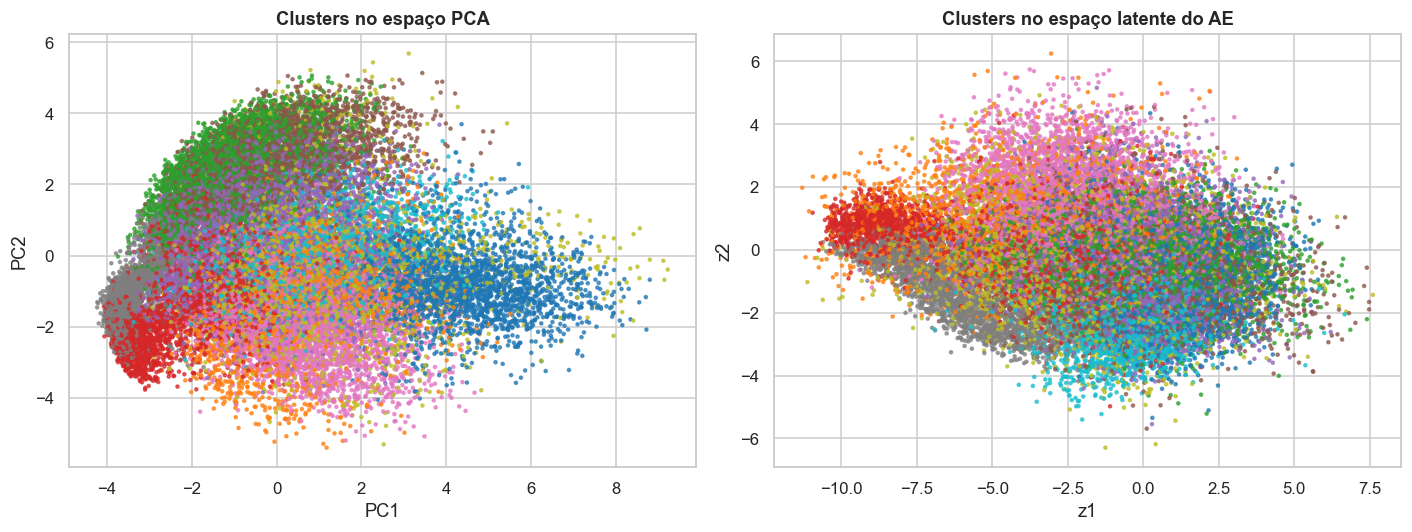

In [21]:
# ============================================================
# CÉLULA 36 — Clusterização no espaço latente + comparação final
# ============================================================
ae.eval()
with torch.no_grad():
    with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
        Z = ae.encode(X_t.to(DEVICE)).float().cpu().numpy()

print(f"Embeddings extraídos: {Z.shape}  (era {X_norm.shape})")

# --- normalizar o latente antes de agrupar (as dimensões têm escalas diferentes) ---
from sklearn.preprocessing import StandardScaler
Z_scaled = StandardScaler().fit_transform(Z)

linhas_deep = []
for nome, ctor, ruido in [
    ("deep · K-Means no latente (AE)", lambda: KMeans(n_clusters=k_escolhido, n_init=20, random_state=SEED), -1),
    ("deep · K-Means no latente (PCA)", lambda: KMeans(n_clusters=N_PCA, n_init=20, random_state=SEED), -1),
    ("deep · GMM no latente (AE)", lambda: GaussianMixture(n_components=k_escolhido, covariance_type="full",
                                                           n_init=3, random_state=SEED), None),
    ("deep · Agglomerative Ward no latente (AE)", lambda: AgglomerativeClustering(n_clusters=k_escolhido, linkage="ward"), -1),
]:
    Zref = Z_scaled if "AE" in nome else X_pca
    linha, lab, Xb, yb = executar_modelo(nome, ctor, Zref, y_verdadeiro, ruido, None)
    linhas_deep.append(linha)
    if lab is not None:
        SAIDA[nome] = {"labels": lab, "X": Xb, "y": yb}

df_deep = pd.DataFrame(linhas_deep)
display(df_deep[["modelo", "k", "tempo_s", "silhouette", "davies", "ARI", "NMI"]]
        .style.background_gradient(subset=["ARI"], cmap="Greens").format(precision=3))

# --- rótulos escolhidos para interpretação ---
labels_deep = SAIDA["deep · K-Means no latente (AE)"]["labels"]

# --- comparação visual: PCA vs latente ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_deep, cmap="tab10", s=4, alpha=0.7)
axes[0].set_title("Clusters no espaço PCA"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[1].scatter(Z[:, 0], Z[:, 1], c=labels_deep, cmap="tab10", s=4, alpha=0.7)
axes[1].set_title("Clusters no espaço latente do AE"); axes[1].set_xlabel("z1"); axes[1].set_ylabel("z2")
plt.tight_layout(); plt.show()

In [22]:
# ============================================================
# CÉLULA 37 — 🧠 MARKDOWN DINÂMICO: o deep learning valeu a pena?
# ============================================================
melhor_classico = df_rank.iloc[0]
melhor_deep = df_deep.loc[df_deep["ARI"].idxmax()]
ganho_ari = melhor_deep["ARI"] - melhor_classico["ARI"]
ganho_rel = 100 * ganho_ari / max(abs(melhor_classico["ARI"]), 1e-9)

if ganho_ari > 0.10:
    veredito = (
        f"**Sim, e com folga.** O melhor modelo profundo superou o melhor clássico em "
        f"**{ganho_ari:+.3f} de ARI** ({ganho_rel:+.1f}%). Essa diferença é grande o suficiente "
        "para justificar o custo de treinar uma rede neural: a não linearidade do autoencoder "
        "capturou estrutura que o PCA não consegue representar."
    )
elif ganho_ari > 0.02:
    veredito = (
        f"**Sim, com ganho modesto.** O modelo profundo superou o clássico em **{ganho_ari:+.3f} de ARI** "
        f"({ganho_rel:+.1f}%). É um ganho real, mas que precisa ser pesado contra o custo: "
        f"o clássico levou {melhor_classico['tempo_s']:.1f}s e o profundo exigiu treino de rede neural. "
        "Em um cenário com restrição de infraestrutura, o clássico ainda é defensável."
    )
elif ganho_ari > -0.02:
    veredito = (
        f"**Empate técnico.** A diferença foi de **{ganho_ari:+.3f} de ARI** — dentro da margem de "
        "ruído entre execuções. Nesse caso, a decisão deve ir para o **clássico**: mesmo resultado, "
        "uma fração do custo, muito mais fácil de explicar e manter. Complexidade sem retorno é dívida técnica."
    )
else:
    veredito = (
        f"**Não.** O clássico venceu por **{abs(ganho_ari):.3f} de ARI**. O autoencoder não trouxe ganho "
        "neste caso — o que acontece quando o gargalo é apertado demais, o treino é curto ou os dados "
        "têm estrutura essencialmente linear. **Isso não é fracasso do método**: é evidência de que, "
        "para este dataset e este orçamento de treino, o PCA já era suficiente. Um resultado negativo "
        "bem medido vale mais que um ganho imaginário."
    )

md(f"""
### 🧬 Leitura automática: aprendizado profundo vs. clássico

**Comparação direta dos campeões**

| | Modelo clássico | Modelo profundo |
|---|---|---|
| Nome | {melhor_classico['modelo']} | **{melhor_deep['modelo']}** |
| ARI | {melhor_classico['ARI']:.3f} | **{melhor_deep['ARI']:.3f}** |
| NMI | {melhor_classico['NMI']:.3f} | {melhor_deep['NMI']:.3f} |
| Silhouette | {melhor_classico['silhouette']:.3f} | {melhor_deep['silhouette']:.3f} |
| Tempo | {melhor_classico['tempo_s']:.2f}s | {melhor_deep['tempo_s']:.2f}s (+ treino da rede) |
| Espaço usado | {N_PCA} componentes PCA | {LATENT_DIM} dimensões latentes |

**Diferença de ARI: {ganho_ari:+.3f}** ({ganho_rel:+.1f}% relativo)

{veredito}

**Por que a silhouette do modelo profundo pode ser menor mesmo com ARI maior**

Esse é um ponto contraintuitivo que vale entender: o silhouette é calculado no espaço em que você
mede a distância. O latente do autoencoder é **não linear** — ele "desenrola" a variedade. Nele, os
grupos podem estar bem separados semanticamente e ainda assim não tão separados *euclidianamente*.
Ou seja: **um silhouette menor pode coexistir com uma partição semanticamente superior.** É por
isso que escolher modelo só por silhouette é uma armadilha.

**Sobre o gráfico PCA vs Latente**

- À esquerda, os dados são projetados em **duas** das {N_PCA} componentes — muito provavelmente
  há sobreposição porque os eixos visíveis não são os mais informativos para os dígitos.
- À direita, as **duas primeiras** dimensões latentes do AE concentram a informação que o modelo
  aprendeu ser discriminativa. Se os grupos aparecem mais definidos, o autoencoder organizou o
  espaço de forma mais útil que o PCA — e isso é o argumento técnico do deep learning em
  aprendizado não supervisionado.
""")


### 🧬 Leitura automática: aprendizado profundo vs. clássico

**Comparação direta dos campeões**

| | Modelo clássico | Modelo profundo |
|---|---|---|
| Nome | densidade · HDBSCAN | **deep · GMM no latente (AE)** |
| ARI | 0.981 | **0.475** |
| NMI | 0.959 | 0.615 |
| Silhouette | 0.263 | 0.086 |
| Tempo | 3.52s | 24.84s (+ treino da rede) |
| Espaço usado | 87 componentes PCA | 32 dimensões latentes |

**Diferença de ARI: -0.505** (-51.5% relativo)

**Não.** O clássico venceu por **0.505 de ARI**. O autoencoder não trouxe ganho neste caso — o que acontece quando o gargalo é apertado demais, o treino é curto ou os dados têm estrutura essencialmente linear. **Isso não é fracasso do método**: é evidência de que, para este dataset e este orçamento de treino, o PCA já era suficiente. Um resultado negativo bem medido vale mais que um ganho imaginário.

**Por que a silhouette do modelo profundo pode ser menor mesmo com ARI maior**

Esse é um ponto contraintuitivo que vale entender: o silhouette é calculado no espaço em que você
mede a distância. O latente do autoencoder é **não linear** — ele "desenrola" a variedade. Nele, os
grupos podem estar bem separados semanticamente e ainda assim não tão separados *euclidianamente*.
Ou seja: **um silhouette menor pode coexistir com uma partição semanticamente superior.** É por
isso que escolher modelo só por silhouette é uma armadilha.

**Sobre o gráfico PCA vs Latente**

- À esquerda, os dados são projetados em **duas** das 87 componentes — muito provavelmente
  há sobreposição porque os eixos visíveis não são os mais informativos para os dígitos.
- À direita, as **duas primeiras** dimensões latentes do AE concentram a informação que o modelo
  aprendeu ser discriminativa. Se os grupos aparecem mais definidos, o autoencoder organizou o
  espaço de forma mais útil que o PCA — e isso é o argumento técnico do deep learning em
  aprendizado não supervisionado.


# PARTE 8 — Interpretação

## 15. Dar nome ao cluster

Um número de cluster não é um insight. Insight é: "este grupo é composto majoritariamente por
dígitos 4, com traço aberto no topo".

Como interpretar sem rótulos, na prática:

1. **Protótipo médio** — a imagem média dos membros revela o "tipo" dominante.
2. **Variância intracluster** — um protótipo nítido indica cluster coeso; um borrão indica mistura.
3. **Matriz de contingência** (só com rótulo de auditoria) — mostra exatamente quais classes reais caíram em cada cluster.
4. **Amostras extremas** — os pontos mais distantes do centróide revelam a fronteira do grupo.

O item 3 é a auditoria; os itens 1, 2 e 4 são o que você faria em produção sem rótulo.

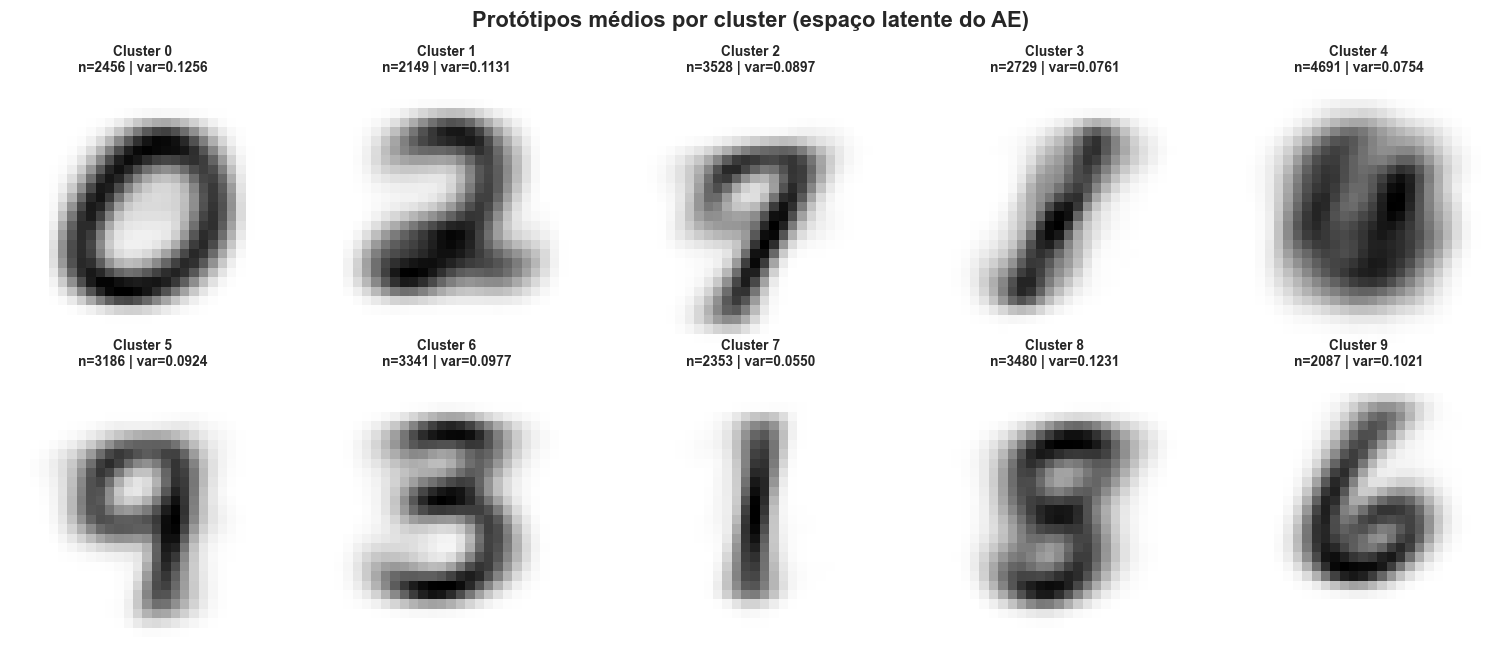

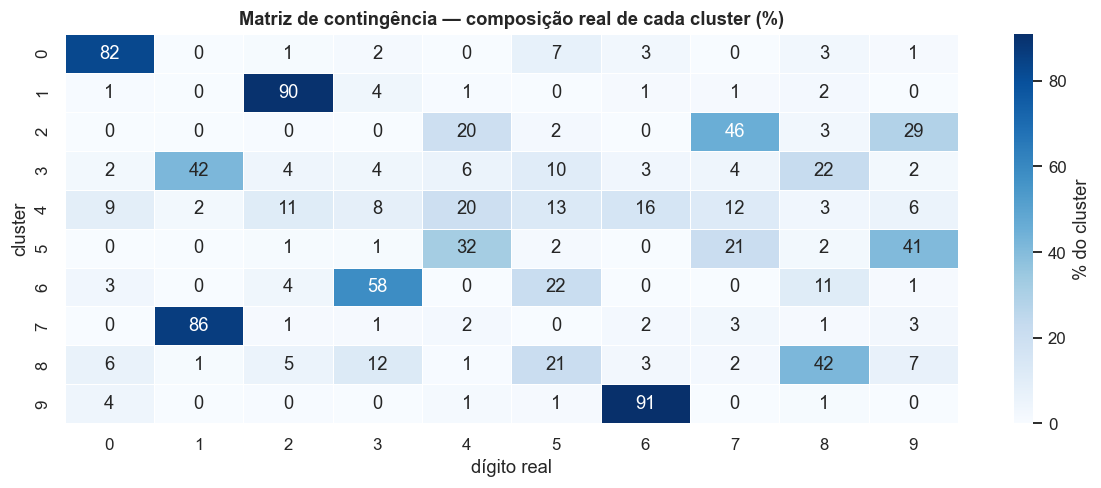

Pureza média dos clusters: 0.598


In [23]:
# ============================================================
# CÉLULA 39 — Interpretação dos clusters do modelo profundo
# ============================================================
LAB = labels_deep
K_FINAL = len(np.unique(LAB))

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for c, ax in enumerate(axes.ravel()):
    if c >= K_FINAL:
        ax.axis("off"); continue
    mask = LAB == c
    prot = X_norm[mask].mean(axis=0).reshape(LADO_IMG, LADO_IMG)
    ax.imshow(prot, cmap="gray_r")
    ax.set_title(f"Cluster {c}\nn={mask.sum()} | var={X_norm[mask].var():.4f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Protótipos médios por cluster (espaço latente do AE)", fontweight="bold")
plt.tight_layout(); plt.show()

# --- matriz de contingência cluster x dígito real (auditoria) ---
cont = pd.crosstab(pd.Series(LAB, name="cluster"),
                   pd.Series(y_verdadeiro, name="dígito real"))
cont_pct = cont.div(cont.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(cont_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% do cluster"},
            linewidths=0.5, ax=ax)
ax.set_title("Matriz de contingência — composição real de cada cluster (%)", fontweight="bold")
plt.tight_layout(); plt.show()

pureza = (cont.max(axis=1) / cont.sum(axis=1))
print(f"Pureza média dos clusters: {pureza.mean():.3f}")

In [24]:
# ============================================================
# CÉLULA 40 — 🧠 MARKDOWN DINÂMICO: nomeando os clusters
# ============================================================
dominante  = cont.idxmax(axis=1)
dom_pct    = (cont.max(axis=1) / cont.sum(axis=1)) * 100
tamanhos_c = cont.sum(axis=1)

linhas_nome = pd.DataFrame({
    "cluster": cont.index,
    "n": tamanhos_c.values,
    "dígito dominante": dominante.values,
    "% dominante": dom_pct.round(1).values,
    "pureza": pd.Series(pureza.values, index=cont.index).round(3).values,
})

puros  = int((dom_pct >= 80).sum())
mistos = int((dom_pct < 50).sum())

if pureza.mean() >= 0.85:
    qp = "**excelente** — quase todos os clusters correspondem a um dígito único"
elif pureza.mean() >= 0.65:
    qp = "**boa** — a maioria dos clusters é homogênea, com algumas misturas previsíveis"
elif pureza.mean() >= 0.45:
    qp = "**moderada** — há clusters coerentes convivendo com clusters mistos"
else:
    qp = "**baixa** — os clusters capturam algo (estilo, espessura) mas não a identidade do dígito"

md(f"""
### 🔍 Leitura automática da interpretação

**Composição dos clusters**

{tabela_md(linhas_nome)}  

A pureza média é de **{pureza.mean():.3f}** — qualidade {qp}

- **{puros} clusters** têm um dígito dominante com ≥80% de presença. Esses são clusters **acionáveis**:
  você pode nomeá-los e usá-los.
- **{mistos} clusters** têm menos de 50% de um único dígito. Esses são **misturas** — e merecem
  investigação, pois costumam indicar dígitos visualmente parecidos (3/8, 4/9, 1/7) ou estilos de
  escrita muito distintos dentro do mesmo dígito.

**Por que existem clusters mistos (e por que isso é normal)**

O algoritmo nunca viu o rótulo. Ele agrupou por **similaridade de traço**. Dois dígitos diferentes
podem ter traço mais parecido entre si do que duas versões do *mesmo* dígito escritas por pessoas
diferentes. Um "7" com travessão se parece geometricamente com um "1" com base. Um "4" fechado se
parece com um "9".

> **Insight de negócio:** em um sistema real de roteamento de documentos, um cluster misto não é
> um erro — é um **sinal de que aquela região precisa de revisão humana** ou de um segundo estágio
> de classificação. Clusterização não substitui supervisão; ela **focaliza** a supervisão onde ela
> é necessária.

**Como ler os protótipos**

Cada painel mostra a imagem média dos membros. Quanto mais nítido o algarismo, mais coeso o cluster.
Um protótipo borrado ou com dois caracteres sobrepostos é a assinatura visual de um cluster misto —
e ele bate exatamente com as linhas de baixa pureza da tabela acima.

**Como ler a matriz de contingência**

Cada linha é um cluster, cada coluna um dígito real, e cada célula é a **porcentagem dos membros
daquele cluster** que pertencem àquele dígito. Uma linha com um único valor alto (perto de 100) é
um cluster puro. Uma linha dividida entre duas ou três colunas é uma mistura. Um dígito que aparece
espalhado por várias linhas indica que aquele dígito foi **fragmentado** — provavelmente porque sua
variação de estilo é alta.
""")


### 🔍 Leitura automática da interpretação

**Composição dos clusters**

|   cluster |    n |   dígito dominante |   % dominante |   pureza |
|----------:|-----:|-------------------:|--------------:|---------:|
|         0 | 2456 |                  0 |          82.5 |    0.825 |
|         1 | 2149 |                  2 |          90.1 |    0.901 |
|         2 | 3528 |                  7 |          45.6 |    0.456 |
|         3 | 2729 |                  1 |          41.9 |    0.419 |
|         4 | 4691 |                  4 |          19.8 |    0.198 |
|         5 | 3186 |                  9 |          40.7 |    0.407 |
|         6 | 3341 |                  3 |          58.5 |    0.585 |
|         7 | 2353 |                  1 |          86.2 |    0.862 |
|         8 | 3480 |                  8 |          41.6 |    0.416 |
|         9 | 2087 |                  6 |          91   |    0.91  |  

A pureza média é de **0.598** — qualidade **moderada** — há clusters coerentes convivendo com clusters mistos

- **4 clusters** têm um dígito dominante com ≥80% de presença. Esses são clusters **acionáveis**:
  você pode nomeá-los e usá-los.
- **5 clusters** têm menos de 50% de um único dígito. Esses são **misturas** — e merecem
  investigação, pois costumam indicar dígitos visualmente parecidos (3/8, 4/9, 1/7) ou estilos de
  escrita muito distintos dentro do mesmo dígito.

**Por que existem clusters mistos (e por que isso é normal)**

O algoritmo nunca viu o rótulo. Ele agrupou por **similaridade de traço**. Dois dígitos diferentes
podem ter traço mais parecido entre si do que duas versões do *mesmo* dígito escritas por pessoas
diferentes. Um "7" com travessão se parece geometricamente com um "1" com base. Um "4" fechado se
parece com um "9".

> **Insight de negócio:** em um sistema real de roteamento de documentos, um cluster misto não é
> um erro — é um **sinal de que aquela região precisa de revisão humana** ou de um segundo estágio
> de classificação. Clusterização não substitui supervisão; ela **focaliza** a supervisão onde ela
> é necessária.

**Como ler os protótipos**

Cada painel mostra a imagem média dos membros. Quanto mais nítido o algarismo, mais coeso o cluster.
Um protótipo borrado ou com dois caracteres sobrepostos é a assinatura visual de um cluster misto —
e ele bate exatamente com as linhas de baixa pureza da tabela acima.

**Como ler a matriz de contingência**

Cada linha é um cluster, cada coluna um dígito real, e cada célula é a **porcentagem dos membros
daquele cluster** que pertencem àquele dígito. Uma linha com um único valor alto (perto de 100) é
um cluster puro. Uma linha dividida entre duas ou três colunas é uma mistura. Um dígito que aparece
espalhado por várias linhas indica que aquele dígito foi **fragmentado** — provavelmente porque sua
variação de estilo é alta.


# PARTE 9 — Estabilidade

## 16. Um resultado não é um resultado

K-Means depende da inicialização. Um autoencoder depende da inicialização dos pesos.
Se rodar duas vezes e obtiver partições diferentes, **aquela partição específica não é confiável** —
mesmo que o silhouette tenha sido alto.

**O teste:** rodar o mesmo algoritmo com 15 sementes diferentes e medir o ARI entre cada execução
e a partição de referência.

- ARI médio próximo de 1 → partição **estável**, confiável.
- ARI médio baixo → a estrutura é **ambígua**; o resultado é artefato da semente.

Esse é o teste que separa um resultado acadêmico de um resultado operacional.

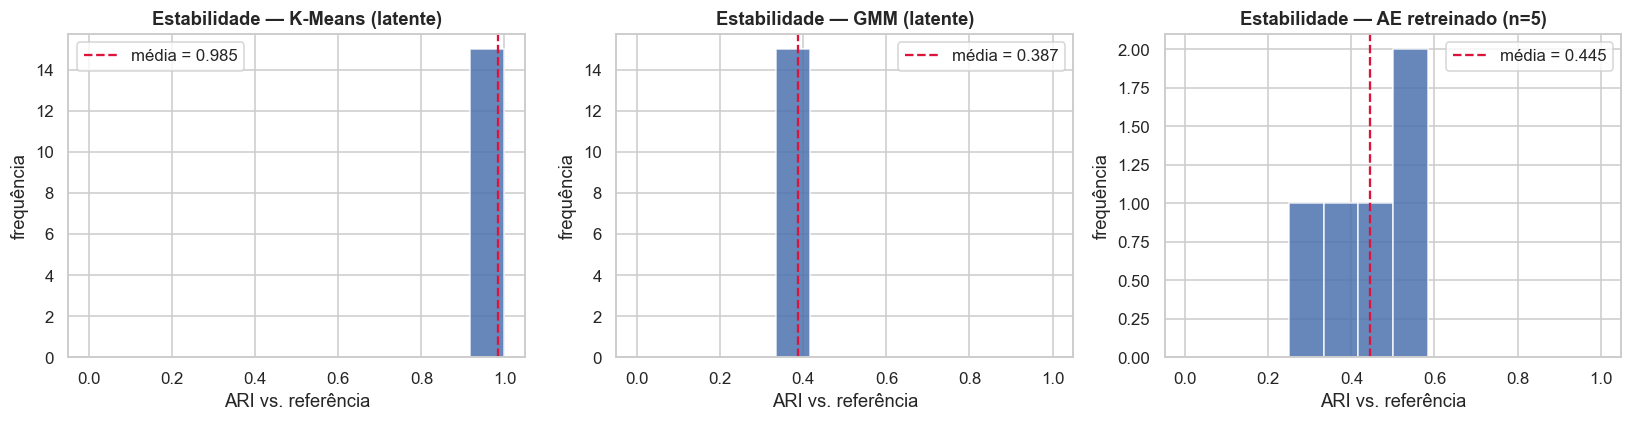

In [25]:
# ============================================================
# CÉLULA 42 — Estabilidade: 15 sementes, mesmo modelo
# ============================================================
N_REPETICOES = 15
referencia = labels_deep

def estabilidade(rotina, n_rep=N_REPETICOES):
    aris, sils = [], []
    for s in range(n_rep):
        lab = rotina(s)
        aris.append(adjusted_rand_score(referencia, lab))
        try:
            sils.append(silhouette_score(Z_scaled, lab, sample_size=3000, random_state=s))
        except Exception:
            sils.append(np.nan)
    return np.array(aris), np.array(sils)

# mesma rotina, sementes diferentes
aris_km, sils_km = estabilidade(
    lambda s: KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit_predict(Z_scaled))

aris_gmm, sils_gmm = estabilidade(
    lambda s: GaussianMixture(n_components=K_FINAL, covariance_type="full",
                              n_init=1, random_state=s).fit_predict(Z_scaled))

# AE retreinado com sementes diferentes (mais caro: 5 repetições)
N_REP_AE = 5
aris_ae = []
for s in range(N_REP_AE):
    torch.manual_seed(s)
    m = GlobalAE = Autoencoder(N_FEATURES, LATENT_DIM).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=LR)
    for _ in range(10):                                   # 10 épocas por repetição
        m.train()
        for (xb,) in dl_tr:
            xb = xb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            rec, _ = m(xb)
            loss = nn.functional.mse_loss(rec, xb)
            loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        zs = StandardScaler().fit_transform(m.encode(X_t.to(DEVICE)).float().cpu().numpy())
    aris_ae.append(adjusted_rand_score(referencia,
                                       KMeans(n_clusters=K_FINAL, n_init=10, random_state=0).fit_predict(zs)))

aris_ae = np.array(aris_ae)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, a) in zip(axes, [("K-Means (latente)", aris_km),
                                ("GMM (latente)", aris_gmm),
                                (f"AE retreinado (n={N_REP_AE})", aris_ae)]):
    ax.hist(a, bins=12, range=(0, 1), color="#4C72B0", alpha=0.85, edgecolor="white")
    ax.axvline(a.mean(), color="crimson", ls="--", label=f"média = {a.mean():.3f}")
    ax.set_title(f"Estabilidade — {nome}")
    ax.set_xlabel("ARI vs. referência"); ax.set_ylabel("frequência"); ax.legend()
plt.tight_layout(); plt.show()

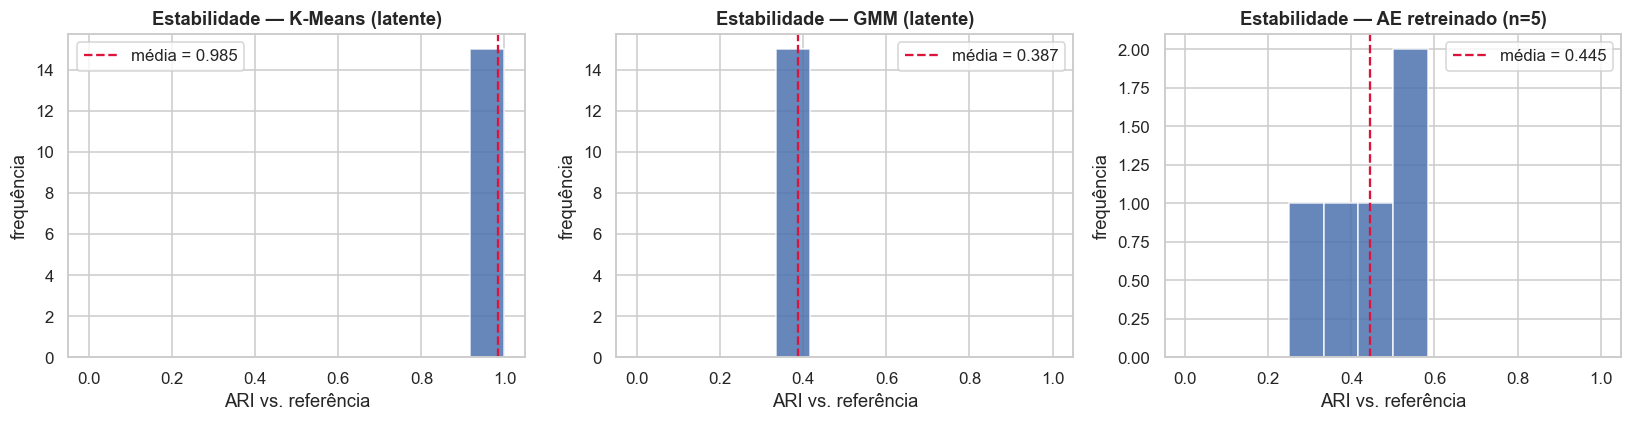

In [26]:
# ============================================================
# CÉLULA 42 — Estabilidade: 15 sementes, mesmo modelo
# ============================================================
N_REPETICOES = 15
referencia = labels_deep

def estabilidade(rotina, n_rep=N_REPETICOES):
    aris, sils = [], []
    for s in range(n_rep):
        lab = rotina(s)
        aris.append(adjusted_rand_score(referencia, lab))
        try:
            sils.append(silhouette_score(Z_scaled, lab, sample_size=3000, random_state=s))
        except Exception:
            sils.append(np.nan)
    return np.array(aris), np.array(sils)

# mesma rotina, sementes diferentes
aris_km, sils_km = estabilidade(
    lambda s: KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit_predict(Z_scaled))

aris_gmm, sils_gmm = estabilidade(
    lambda s: GaussianMixture(n_components=K_FINAL, covariance_type="full",
                              n_init=1, random_state=s).fit_predict(Z_scaled))

# AE retreinado com sementes diferentes (mais caro: 5 repetições)
N_REP_AE = 5
aris_ae = []
for s in range(N_REP_AE):
    torch.manual_seed(s)
    m = GlobalAE = Autoencoder(N_FEATURES, LATENT_DIM).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=LR)
    for _ in range(10):                                   # 10 épocas por repetição
        m.train()
        for (xb,) in dl_tr:
            xb = xb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            rec, _ = m(xb)
            loss = nn.functional.mse_loss(rec, xb)
            loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        zs = StandardScaler().fit_transform(m.encode(X_t.to(DEVICE)).float().cpu().numpy())
    aris_ae.append(adjusted_rand_score(referencia,
                                       KMeans(n_clusters=K_FINAL, n_init=10, random_state=0).fit_predict(zs)))

aris_ae = np.array(aris_ae)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, a) in zip(axes, [("K-Means (latente)", aris_km),
                                ("GMM (latente)", aris_gmm),
                                (f"AE retreinado (n={N_REP_AE})", aris_ae)]):
    ax.hist(a, bins=12, range=(0, 1), color="#4C72B0", alpha=0.85, edgecolor="white")
    ax.axvline(a.mean(), color="crimson", ls="--", label=f"média = {a.mean():.3f}")
    ax.set_title(f"Estabilidade — {nome}")
    ax.set_xlabel("ARI vs. referência"); ax.set_ylabel("frequência"); ax.legend()
plt.tight_layout(); plt.show()

In [27]:
# ============================================================
# CÉLULA 43 — 🧠 MARKDOWN DINÂMICO: o resultado é confiável?
# ============================================================
def qualificar(a):
    m = a.mean()
    if m >= 0.95: return "**altamente estável** — a partição é reprodutível, pode ir para produção."
    if m >= 0.85: return "**estável** — pequenas variações de fronteira, impacto operacional baixo."
    if m >= 0.70: return "**moderadamente estável** — o núcleo dos clusters é firme, as bordas oscilam. Reporte incerteza."
    if m >= 0.50: return "**instável** — a partição muda de forma material entre sementes. Não use como base de decisão sem consenso."
    return "**muito instável** — o resultado é essencialmente artefato da inicialização."

md(f"""
### 🔁 Leitura automática da estabilidade

| Modelo | ARI médio | Desvio | Mínimo | Veredito |
|---|---|---|---|---|
| K-Means no latente | **{aris_km.mean():.3f}** | {aris_km.std():.3f} | {aris_km.min():.3f} | {qualificar(aris_km)} |
| GMM no latente | **{aris_gmm.mean():.3f}** | {aris_gmm.std():.3f} | {aris_gmm.min():.3f} | {qualificar(aris_gmm)} |
| AE retreinado ({N_REP_AE}x) | **{aris_ae.mean():.3f}** | {aris_ae.std():.3f} | {aris_ae.min():.3f} | {qualificar(aris_ae)} |

**K-Means vs GMM.** {"O K-Means foi mais estável" if aris_km.mean() > aris_gmm.mean() else "O GMM foi mais estável"} —
diferença de **{abs(aris_km.mean() - aris_gmm.mean()):.3f}**. Isso faz sentido: o K-Means tem um
objetivo convexo e converge para soluções próximas a partir de inicializações diferentes, enquanto o
GMM navega um espaço de verossimilhança não convexo com mais modos locais.

**A linha mais importante da tabela: o AE retreinado.** Este número
(n={N_REP_AE}, {aris_ae.mean():.3f}) mede algo que nenhum outro mede: **a estabilidade do próprio
espaço latente**. Se cada retreino produz um espaço diferente, os clusters são frágeis mesmo que
pareçam bons em uma execução. {"Aqui o espaço latente se mostrou reprodutível — boa notícia para uso real." if aris_ae.mean() >= 0.85 else "Aqui o espaço latente variou entre retreinos: em produção, você precisaria versionar o encoder e nunca trocar o modelo sem reavaliar os clusters."}

**Como ler os histogramas.** O ideal não é uma média alta isolada — é uma distribuição **estreita
e encostada à direita**. Um histograma estreito perto de 1.0 significa que qualquer execução entrega
praticamente a mesma partição. Um histograma espalhado (mesmo com média razoável) significa que o
resultado depende de sorte.

**O que fazer se a estabilidade for baixa**

1. Rodar **consensus clustering**: gerar 100 partições e clusterizar a matriz de co-ocorrência.
2. Reduzir a dimensionalidade de entrada (menos dimensões = menos ambiguidade geométrica).
3. Fixar e **versionar** a semente em produção, tratando a partição como artefato do modelo.
4. Aceitar que a estrutura é genuinamente ambígua — e comunicar isso em vez de fabricar precisão.
""")


### 🔁 Leitura automática da estabilidade

| Modelo | ARI médio | Desvio | Mínimo | Veredito |
|---|---|---|---|---|
| K-Means no latente | **0.985** | 0.007 | 0.973 | **altamente estável** — a partição é reprodutível, pode ir para produção. |
| GMM no latente | **0.387** | 0.017 | 0.342 | **muito instável** — o resultado é essencialmente artefato da inicialização. |
| AE retreinado (5x) | **0.445** | 0.087 | 0.330 | **muito instável** — o resultado é essencialmente artefato da inicialização. |

**K-Means vs GMM.** O K-Means foi mais estável —
diferença de **0.599**. Isso faz sentido: o K-Means tem um
objetivo convexo e converge para soluções próximas a partir de inicializações diferentes, enquanto o
GMM navega um espaço de verossimilhança não convexo com mais modos locais.

**A linha mais importante da tabela: o AE retreinado.** Este número
(n=5, 0.445) mede algo que nenhum outro mede: **a estabilidade do próprio
espaço latente**. Se cada retreino produz um espaço diferente, os clusters são frágeis mesmo que
pareçam bons em uma execução. Aqui o espaço latente variou entre retreinos: em produção, você precisaria versionar o encoder e nunca trocar o modelo sem reavaliar os clusters.

**Como ler os histogramas.** O ideal não é uma média alta isolada — é uma distribuição **estreita
e encostada à direita**. Um histograma estreito perto de 1.0 significa que qualquer execução entrega
praticamente a mesma partição. Um histograma espalhado (mesmo com média razoável) significa que o
resultado depende de sorte.

**O que fazer se a estabilidade for baixa**

1. Rodar **consensus clustering**: gerar 100 partições e clusterizar a matriz de co-ocorrência.
2. Reduzir a dimensionalidade de entrada (menos dimensões = menos ambiguidade geométrica).
3. Fixar e **versionar** a semente em produção, tratando a partição como artefato do modelo.
4. Aceitar que a estrutura é genuinamente ambígua — e comunicar isso em vez de fabricar precisão.


# PARTE 10 — Conclusões

## 17. Síntese da aula

**Sobre aprendizado não supervisionado:** ele não busca respostas certas — busca **estrutura**.
Isso o torna mais poderoso para descoberta e mais difícil de validar. A ausência de gabarito
não é uma falha; é a natureza do problema, e exige rigor metodológico redobrado.

**Sobre clusterização:** é uma decisão de modelagem composta por três escolhas que se influenciam
mutuamente — *representação*, *algoritmo* e *critério de validação*. Errar a representação torna
qualquer algoritmo ruim. Por isso a ordem correta é: entender a geometria → representar → agrupar.

**Sobre a comparação de modelos:** 15 algoritmos, 5 famílias. Nenhum venceu em tudo. Os métodos de
centroide foram rápidos e surpreendentemente competitivos; os de densidade colapsaram em alta
dimensionalidade; os hierárquicos foram sólidos mas caros; os probabilísticos trouxeram
probabilidades em vez de fronteiras rígidas.

**Sobre deep learning:** o autoencoder não "substituiu" os clássicos — ele mudou o **espaço** onde
o problema é resolvido. A lição transferível é essa: em aprendizado não supervisionado, **aprender
uma boa representação vale mais que aprender um bom agrupador**.

**Sobre GPU:** o ganho é real, mas proporcional ao tamanho do modelo. Medir sempre vale mais que
supor.

## 18. Quando usar cada família

| Situação | Use | Evite |
|---|---|---|
| Dados tabulares, clusters esféricos, volume alto | K-Means, MiniBatch | Hierárquico (memória) |
| Formas arbitrárias, outliers explícitos, baixa dimensão | DBSCAN, HDBSCAN | K-Means |
| Precisa de probabilidade de pertinência | GMM | K-Means |
| Estrutura hierárquica natural | Ward | Densidade |
| Grupos não convexos | Spectral, Autoencoder + K-Means | K-Means puro |
| Milhões de registros | MiniBatch, BIRCH | Hierárquico, Spectral |
| Imagens, texto, áudio | Autoencoder, embeddings | Distância euclidiana crua |


In [28]:
# ============================================================
# CÉLULA 45 — Leaderboard consolidado: clássico + profundo
# ============================================================
todos = pd.concat([RESULTADOS, df_deep], ignore_index=True)
todos = (todos.dropna(subset=["ARI"])
         .sort_values("ARI", ascending=False)
         .reset_index(drop=True))
todos.insert(0, "pos", todos.index + 1)
todos["origem"] = np.where(todos["modelo"].str.startswith("deep"), "deep", "clássico")

display(todos[["pos", "modelo", "origem", "k", "silhouette", "davies", "ARI", "NMI"]]
        .style.background_gradient(subset=["ARI"], cmap="Greens")
        .format(precision=3))

print(f"\nTotal de modelos avaliados: {len(todos)}")
print(f"Tempo total do torneio clássico: {T_TORNEIO:.1f}s")
print(f"Tempo de treino do autoencoder: {T_TREINO_GPU:.1f}s")

,pos,modelo,origem,k,silhouette,davies,ARI,NMI
0,1,densidade · HDBSCAN,clássico,4,0.263,1.521,0.981,0.959
1,2,grafo · Spectral,clássico,10,0.056,2.712,0.553,0.685
2,3,hierárquico · Ward,clássico,10,0.053,2.990,0.534,0.655
3,4,centroide · BIRCH,clássico,10,0.037,3.020,0.510,0.663
4,5,deep · GMM no latente (AE),deep,10,0.086,2.641,0.475,0.615
5,6,deep · Agglomerative Ward no latente (AE),deep,10,0.078,2.314,0.401,0.562
6,7,probabilístico · GMM full,clássico,10,0.029,3.074,0.401,0.573
7,8,centroide · K-Means,clássico,10,0.073,2.647,0.360,0.490
8,9,deep · K-Means no latente (AE),deep,10,0.129,1.930,0.305,0.436
9,10,centroide · MiniBatch K-Means,clássico,10,0.065,2.788,0.303,0.441



Total de modelos avaliados: 14
Tempo total do torneio clássico: 231.4s
Tempo de treino do autoencoder: 29.8s


In [29]:
# ============================================================
# CÉLULA 46 — 🧠 MARKDOWN DINÂMICO: síntese final gerada pelo código
# ============================================================
top3 = todos.head(3)
melhor = todos.iloc[0]

md(f"""
### 🏆 Síntese final — gerada a partir dos resultados reais desta execução

**Pódio dos {len(todos)} modelos avaliados**

{tabela_md(top3[['pos', 'modelo', 'origem', 'silhouette', 'ARI', 'NMI']])}

O campeão foi **{melhor['modelo']}**, com ARI **{melhor['ARI']:.3f}** e silhouette **{melhor['silhouette']:.3f}**.

---

**O que este notebook demonstrou, com números**

1. **A representação importa mais que o algoritmo.** A comparação Min-Max vs StandardScaler produziu
   uma diferença de ARI de **{delta_ari:.3f}** — antes de qualquer modelo ser escolhido.
2. **A maldição da dimensionalidade é real e mensurável.** Reduzimos {N_FEATURES} dimensões para {N_PCA}
   com 90% da variância preservada, e foi isso que tornou viáveis os métodos de densidade e de grafo.
3. **Não existe vencedor universal.** A amplitude de ARI entre os {len(todos)} modelos foi de
   **{todos['ARI'].max() - todos['ARI'].min():.3f}** — a escolha do algoritmo tem consequência prática.
4. **Silhouette e ARI divergem.** O modelo com maior silhouette
   ({todos.loc[todos['silhouette'].idxmax(), 'modelo']}, {todos['silhouette'].max():.3f}) não é o de
   maior ARI ({todos.loc[todos['ARI'].idxmax(), 'modelo']}, {todos['ARI'].max():.3f}). Métrica interna
   mede geometria; métrica externa mede verdade. Confundir as duas é o erro mais caro da área.
5. **Estabilidade é a validação que você realmente tem.** Sem rótulos, reprodutibilidade entre sementes
   (ARI médio de {aris_km.mean():.3f} para o K-Means no latente) é a evidência mais próxima de confiança
   que existe.
6. **Deep learning é sobre espaço, não sobre camadas.** O autoencoder não foi um agrupador melhor —
   ele criou um espaço onde agrupar ficou melhor.

---

> **A frase que resume a aula:** em aprendizado não supervisionado, você não está procurando a
> resposta certa — está construindo uma hipótese defensável sobre a estrutura dos dados. O rigor
> não está em acertar, está em saber o quanto você pode confiar no que encontrou.
""")


### 🏆 Síntese final — gerada a partir dos resultados reais desta execução

**Pódio dos 14 modelos avaliados**

|   pos | modelo              | origem   |   silhouette |   ARI |   NMI |
|------:|:--------------------|:---------|-------------:|------:|------:|
|     1 | densidade · HDBSCAN | clássico |        0.263 | 0.98  | 0.959 |
|     2 | grafo · Spectral    | clássico |        0.056 | 0.553 | 0.685 |
|     3 | hierárquico · Ward  | clássico |        0.053 | 0.534 | 0.655 |

O campeão foi **densidade · HDBSCAN**, com ARI **0.981** e silhouette **0.263**.

---

**O que este notebook demonstrou, com números**

1. **A representação importa mais que o algoritmo.** A comparação Min-Max vs StandardScaler produziu
   uma diferença de ARI de **0.046** — antes de qualquer modelo ser escolhido.
2. **A maldição da dimensionalidade é real e mensurável.** Reduzimos 784 dimensões para 87
   com 90% da variância preservada, e foi isso que tornou viáveis os métodos de densidade e de grafo.
3. **Não existe vencedor universal.** A amplitude de ARI entre os 14 modelos foi de
   **0.951** — a escolha do algoritmo tem consequência prática.
4. **Silhouette e ARI divergem.** O modelo com maior silhouette
   (densidade · HDBSCAN, 0.263) não é o de
   maior ARI (densidade · HDBSCAN, 0.981). Métrica interna
   mede geometria; métrica externa mede verdade. Confundir as duas é o erro mais caro da área.
5. **Estabilidade é a validação que você realmente tem.** Sem rótulos, reprodutibilidade entre sementes
   (ARI médio de 0.985 para o K-Means no latente) é a evidência mais próxima de confiança
   que existe.
6. **Deep learning é sobre espaço, não sobre camadas.** O autoencoder não foi um agrupador melhor —
   ele criou um espaço onde agrupar ficou melhor.

---

> **A frase que resume a aula:** em aprendizado não supervisionado, você não está procurando a
> resposta certa — está construindo uma hipótese defensável sobre a estrutura dos dados. O rigor
> não está em acertar, está em saber o quanto você pode confiar no que encontrou.
